# **Project Name**    -   Paisabazaar Banking Fraud Analysis: Credit Score Exploratory Data Analysis & Classification

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##### **Project Type**    - EDA + Classification
##### **Contribution**    - Individual [Fatima Firdous]

# **Project Summary -**

Paisabazaar is a financial-services marketplace that helps customers find and apply for banking and credit products. A customer's credit score decides whether a loan is approved, at what interest rate, and how much default risk the company carries. This project analyses a dataset of **100,000 monthly records for 12,500 customers (8 months each, 28 columns)** to understand what drives a customer's credit score (*Poor, Standard* or *Good*) and then builds a model that predicts it.

**Data understanding.** The data has no null values and no duplicate rows. Two columns hide missing information behind placeholder text: `Payment_of_Min_Amount = "NM"` (12,007 rows) and `Type_of_Loan = "No Data"` (11,408 rows). The target is moderately imbalanced: 53.2% Standard, 29.0% Poor, 17.8% Good. Identifiers (`ID`, `Name`, `SSN`) were dropped; `Credit_History_Age` was converted from months to years; and new ratio features were engineered (debt-to-income, EMI-to-salary, savings ratio, number of loan types).

**Exploratory analysis.** Fifteen charts were produced following the UBM rule (Univariate, Bivariate, Multivariate), including histograms, count plots, donut/bar charts, stacked bars, box and violin plots, scatter plots, a correlation heatmap and a pair plot. The key findings are consistent across charts:
- **Credit mix is the strongest single signal.** 60% of customers with a *Bad* mix have a Poor score, while 49% of those with a *Good* mix have a Good score.
- **Poor-score customers pay more and pay later.** Average interest rate is 20.2% (Poor) vs 7.7% (Good), and average payment delay is 29.7 vs 11.0 days.
- **Debt and loan count rise as score falls.** Outstanding debt averages about 2,081 for Poor customers vs 801 for Good; Poor customers hold 4.8 loans on average vs 2.2.
- **Income and history help.** Good-score customers earn about 65,200 a year on average vs 40,600 for Poor, and have about 285 months of credit history vs 170.
- **Occupation barely matters** and credit utilisation is almost identical across groups, so neither is a useful screening variable on its own.
- Income and monthly investment are strongly correlated (r = 0.81), and interest rate, loan count, debt and inquiries move together (r of about 0.6).

**Hypothesis testing.** Three tests, all significant at 5%: Mann-Whitney U (Good-score customers earn more than Poor-score customers), Chi-square (credit score depends on credit mix, Cramer's V = 0.45, a strong association) and Kruskal-Wallis with Bonferroni post-hoc (outstanding debt differs between every pair of score groups).

**Modelling.** After outlier capping (IQR), log/square-root transformation of skewed variables, encoding and scaling inside a leakage-safe pipeline, the data was split 80/20 **by customer** so no person appears in both training and test sets. Class weights handled the imbalance. Logistic Regression, Random Forest and Gradient Boosting were trained and tuned with group-aware cross-validation. The tuned **Random Forest** was selected: 69.0% accuracy, macro-F1 of 0.681 and macro-recall of 0.717, ahead of Logistic Regression (66.0% / 0.653). Permutation importance shows credit mix, interest rate, payment delay, outstanding debt and credit-history length as the most influential features. The model was saved with joblib and reloaded successfully for a sanity check.

**Business value.** Paisabazaar can use these insights to pre-screen applicants, price risk-based interest rates, flag customers with rising delays or debt for early intervention, and recommend products to customers with a good profile, while using the model as a decision-support tool alongside human credit review rather than a replacement for it.

# **GitHub Link -**

https://github.com/fatimafirdous944/paisabazaar-credit-score-EDA

# **Problem Statement**

**Paisabazaar needs to assess the creditworthiness of individuals accurately to improve loan approval decisions and manage default risk. Using customer data such as income, number of loans and credit cards, interest rate, payment delays, outstanding debt, credit utilisation, credit history and payment behaviour, this project (1) explores the data to find what separates customers with Poor, Standard and Good credit scores, and (2) builds a model that predicts a customer's credit score class.**

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [2]:
# Import Libraries
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")                     # keep the notebook output clean
sns.set_theme(style="whitegrid", palette="deep")      # consistent chart style
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42                                     # reproducibility
SCORE_ORDER = ["Poor", "Standard", "Good"]            # logical order of the target
SCORE_COLORS = {"Poor": "#d62728", "Standard": "#ff9f1c", "Good": "#2ca02c"}

### Dataset Loading

In [3]:
# Load Dataset
# The notebook looks for the CSV in the usual places (Colab upload, Google Drive, local folder)
CANDIDATE_PATHS = [
    "dataset-2.csv",
    "/content/dataset-2.csv",
    "/content/drive/MyDrive/PaisaBazaar Project/dataset-2.csv",
    "/mnt/user-data/uploads/dataset-2.csv",
]

def load_data(paths):
    """Return the dataframe from the first path that exists; raise a clear error otherwise."""
    for p in paths:
        if os.path.exists(p):
            print(f"Loaded data from: {p}")
            return pd.read_csv(p)
    raise FileNotFoundError("dataset-2.csv not found. Upload it to Colab (or mount Drive) and re-run.")

try:
    df = load_data(CANDIDATE_PATHS)
except FileNotFoundError as err:
    print(err)
    raise

Loaded data from: dataset-2.csv


### Dataset First View

In [4]:
# Dataset First Look
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


In [5]:
# Dataset Last Look
df.tail()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
99995,155625,37932,4,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.663572,378.0,No,35.104023,24.028477,High_spent_Large_value_payments,479.866228,Poor
99996,155626,37932,5,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,40.565631,379.0,No,35.104023,24.028477,High_spent_Medium_value_payments,496.651610,Poor
99997,155627,37932,6,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,41.255522,380.0,No,35.104023,24.028477,High_spent_Large_value_payments,516.809083,Poor
99998,155628,37932,7,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,33.638208,381.0,No,35.104023,24.028477,Low_spent_Large_value_payments,319.164979,Standard
99999,155629,37932,8,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.192463,382.0,No,35.104023,24.028477,High_spent_Medium_value_payments,393.673696,Poor


### Dataset Rows & Columns count

In [6]:
# Dataset Rows & Columns count
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

Rows    : 100,000
Columns : 28


### Dataset Information

In [7]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

#### Duplicate Values

In [8]:
# Dataset Duplicate Value Count
print("Fully duplicated rows      :", df.duplicated().sum())
print("Duplicated (ID) values     :", df["ID"].duplicated().sum())
print("Unique customers           :", df["Customer_ID"].nunique())
print("Rows per customer (min/max):", df.groupby("Customer_ID").size().min(), "/", df.groupby("Customer_ID").size().max())

Fully duplicated rows      : 0
Duplicated (ID) values     : 0
Unique customers           : 12500
Rows per customer (min/max): 8 / 8


#### Missing Values/Null Values

In [9]:
# Missing Values/Null Values Count
null_counts = df.isnull().sum()
print("Total missing values:", null_counts.sum())
null_counts[null_counts > 0] if null_counts.sum() else null_counts.to_frame("missing_count").T

Total missing values: 0


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
missing_count,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


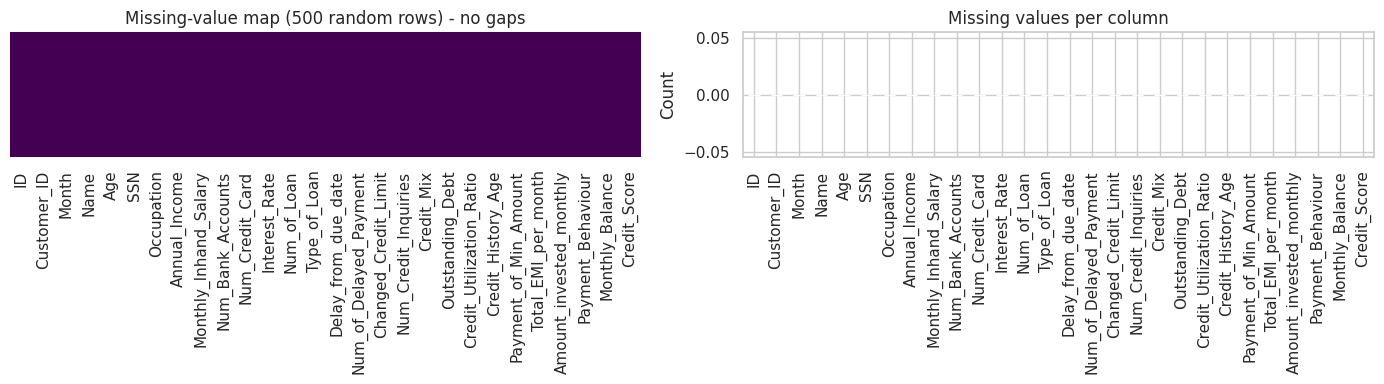

Payment_of_Min_Amount == 'NM' : 12007 rows
Type_of_Loan == 'No Data'     : 11408 rows


In [10]:
# Visualizing the missing values
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(df.sample(500, random_state=RANDOM_STATE).isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=ax[0])
ax[0].set_title("Missing-value map (500 random rows) - no gaps")
null_counts.plot(kind="bar", ax=ax[1], color="steelblue")
ax[1].set_title("Missing values per column")
ax[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

# Hidden 'placeholder' categories (data is not NaN but carries no information)
print("Payment_of_Min_Amount == 'NM' :", (df["Payment_of_Min_Amount"] == "NM").sum(), "rows")
print("Type_of_Loan == 'No Data'     :", (df["Type_of_Loan"] == "No Data").sum(), "rows")

### What did you know about your dataset?

**Overview**
- The dataset has **100,000 rows x 28 columns**: 12,500 customers observed for 8 consecutive months (every customer has exactly 8 rows). It is therefore a *panel* (repeated-measures) dataset, which is why the train/test split is done by customer.
- **No NaN values and no duplicate rows.** Two columns hide missing information as text: `Payment_of_Min_Amount = "NM"` (12,007 rows, "not mentioned") and `Type_of_Loan = "No Data"` (11,408 rows, matching customers with 0 loans).
- Column types: 20 numeric columns, 7 text columns (`Name`, `Occupation`, `Type_of_Loan`, `Credit_Mix`, `Payment_of_Min_Amount`, `Payment_Behaviour`, `Credit_Score`) and identifiers.
- **Target = `Credit_Score`** with three classes: Standard (53.2%), Poor (29.0%), Good (17.8%), a moderately imbalanced multi-class problem.
- `Annual_Income` and `Monthly_Inhand_Salary` are almost perfectly correlated (r = 0.998), so one is redundant.
- `Type_of_Loan` is free text listing several products per customer (e.g. "Auto Loan, Credit-Builder Loan, ...") and needs to be converted into a count.

## ***2. Understanding Your Variables***

In [11]:
# Dataset Columns
print(list(df.columns))

['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']


In [12]:
# Dataset Describe
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,100000.0,8.063150e+04,4.330149e+04,5634.00,4.313275e+04,8.063150e+04,1.181302e+05,1.556290e+05
Customer_ID,100000.0,2.598267e+04,1.434054e+04,1006.00,1.366450e+04,2.577700e+04,3.838500e+04,5.099900e+04
Month,100000.0,4.500000e+00,2.290000e+00,1.00,2.750000e+00,4.500000e+00,6.250000e+00,8.000000e+00
Age,100000.0,3.332000e+01,1.076000e+01,14.00,2.400000e+01,3.300000e+01,4.200000e+01,5.600000e+01
SSN,100000.0,5.004617e+08,2.908267e+08,81349.00,2.451686e+08,5.006886e+08,7.560027e+08,9.999934e+08
Annual_Income,100000.0,5.050512e+04,3.829942e+04,7005.93,1.934297e+04,3.699970e+04,7.168347e+04,1.799873e+05
Monthly_Inhand_Salary,100000.0,4.197270e+03,3.186430e+03,303.65,1.626590e+03,3.095900e+03,5.957720e+03,1.520463e+04
Num_Bank_Accounts,100000.0,5.370000e+00,2.590000e+00,0.00,3.000000e+00,5.000000e+00,7.000000e+00,1.100000e+01
Num_Credit_Card,100000.0,5.530000e+00,2.070000e+00,0.00,4.000000e+00,5.000000e+00,7.000000e+00,1.100000e+01
Interest_Rate,100000.0,1.453000e+01,8.740000e+00,1.00,7.000000e+00,1.300000e+01,2.000000e+01,3.400000e+01


### Variables Description

| Variable | Meaning |
|---|---|
| ID, Customer_ID, Month, Name, SSN | Record / customer identifiers and the month of observation (1-8); no predictive value |
| Age, Occupation | Customer demographics (age 14-56; 15 occupations) |
| Annual_Income, Monthly_Inhand_Salary | Yearly income and take-home monthly salary |
| Num_Bank_Accounts, Num_Credit_Card | Number of bank accounts / credit cards held |
| Interest_Rate | Interest rate (%) charged on the customer's credit |
| Num_of_Loan, Type_of_Loan | Count and the kinds of loans taken |
| Delay_from_due_date | Average days payments are late from the due date |
| Num_of_Delayed_Payment | Number of payments that were delayed |
| Changed_Credit_Limit | Percentage change in credit limit |
| Num_Credit_Inquiries | Number of credit enquiries (applications) made |
| Credit_Mix | Quality of the mix of credit products: Bad / Standard / Good |
| Outstanding_Debt | Remaining debt owed |
| Credit_Utilization_Ratio | Share of available credit that is used (%) |
| Credit_History_Age | Length of credit history in months |
| Payment_of_Min_Amount | Whether the customer pays only the minimum due amount (Yes / No / NM = not mentioned) |
| Total_EMI_per_month | Total monthly EMI obligations |
| Amount_invested_monthly | Amount invested each month |
| Payment_Behaviour | Spending level (Low/High) combined with payment size (Small/Medium/Large) |
| Monthly_Balance | Monthly balance left in the account |
| **Credit_Score** | **Target: Poor / Standard / Good** |

### Check Unique Values for each variable.

In [13]:
# Check Unique Values for each variable.
unique_df = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique()})
unique_df["sample_values"] = [list(df[c].dropna().unique()[:4]) for c in df.columns]
unique_df

,dtype,n_unique,sample_values
ID,int64,100000,"[5634, 5635, 5636, 5637]"
Customer_ID,int64,12500,"[3392, 8625, 11708, 47249]"
Month,int64,8,"[1, 2, 3, 4]"
Name,object,10128,"[Aaron Maashoh, Rick Rothackerj, Langep, Jasond]"
Age,float64,43,"[23.0, 28.0, 34.0, 54.0]"
SSN,float64,12500,"[821000265.0, 4075839.0, 486853974.0, 72316145.0]"
Occupation,object,15,"[Scientist, Teacher, Engineer, Entrepreneur]"
Annual_Income,float64,12488,"[19114.12, 34847.84, 143162.64, 30689.89]"
Monthly_Inhand_Salary,float64,13241,"[1824.8433333333328, 3037.986666666666, 12187...."
Num_Bank_Accounts,float64,12,"[3.0, 2.0, 1.0, 7.0]"


## 3. ***Data Wrangling***

### Data Wrangling Code

In [14]:
# Write your code to make your dataset analysis ready.
data = df.copy()

# 1. Drop identifiers / personal data that carry no predictive signal (and would leak identity)
data = data.drop(columns=["ID", "Name", "SSN"])

# 2. Standardise data types
for col in ["Age", "Num_Bank_Accounts", "Num_Credit_Card", "Num_of_Loan", "Num_of_Delayed_Payment",
            "Num_Credit_Inquiries", "Credit_History_Age", "Delay_from_due_date", "Interest_Rate"]:
    data[col] = data[col].astype(int)

# 3. Convert credit history from months to years (easier to read)
data["Credit_History_Years"] = (data["Credit_History_Age"] / 12).round(2)

# 4. Make the target an ordered category (Poor < Standard < Good)
data["Credit_Score"] = pd.Categorical(data["Credit_Score"], categories=SCORE_ORDER, ordered=True)

# 5. Clean the loan-type text and count how many distinct loan types each record holds
def count_loan_types(text):
    """Count distinct loan products in the free-text Type_of_Loan column."""
    if text in ("No Data", "Not Specified"):
        return 0
    parts = [p.replace("and ", "").strip() for p in text.split(",")]
    return len(set(p for p in parts if p))
data["Loan_Types_Count"] = data["Type_of_Loan"].apply(count_loan_types)

# 6. Engineered ratio features (business-meaningful)
data["Debt_to_Income"]  = data["Outstanding_Debt"] / data["Annual_Income"]                       # debt burden
data["EMI_to_Salary"]   = data["Total_EMI_per_month"] / data["Monthly_Inhand_Salary"]            # repayment burden
data["Savings_Ratio"]   = (data["Amount_invested_monthly"] + data["Monthly_Balance"]) / data["Monthly_Inhand_Salary"]

print("Analysis-ready shape:", data.shape)
data.head()

Analysis-ready shape: (100000, 30)


,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,...,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,Credit_History_Years,Loan_Types_Count,Debt_to_Income,EMI_to_Salary,Savings_Ratio
0,3392,1,23,Scientist,19114.12,1824.843333,3,4,3,4,...,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good,22.08,4,0.042376,0.027167,0.183007
1,3392,2,23,Scientist,19114.12,1824.843333,3,4,3,4,...,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good,22.17,4,0.042376,0.027167,0.167737
2,3392,3,23,Scientist,19114.12,1824.843333,3,4,3,4,...,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good,22.25,4,0.042376,0.027167,0.193263
3,3392,4,23,Scientist,19114.12,1824.843333,3,4,3,4,...,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good,22.33,4,0.042376,0.027167,0.134212
4,3392,5,23,Scientist,19114.12,1824.843333,3,4,3,4,...,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good,22.42,4,0.042376,0.027167,0.198896


### What all manipulations have you done and insights you found?

**Manipulations performed**
1. Dropped `ID`, `Name`, `SSN`: identifiers/personal data with no predictive value (and a privacy risk).
2. Converted count-type columns to integers.
3. Converted `Credit_History_Age` from months to years (`Credit_History_Years`).
4. Made `Credit_Score` an ordered category (Poor < Standard < Good).
5. Converted the free-text `Type_of_Loan` into `Loan_Types_Count`.
6. Engineered ratio features: `Debt_to_Income`, `EMI_to_Salary` and `Savings_Ratio`.

**Insights**
- Every customer has exactly 8 months, so the data is balanced across time.
- "NM" and "No Data" are *information*, not noise, so they are kept as their own categories.
- The ratio features express financial burden relative to income, which is closer to how a lender thinks than raw amounts.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

### **UNIVARIATE ANALYSIS**

#### Chart - 1 : Credit Score Distribution

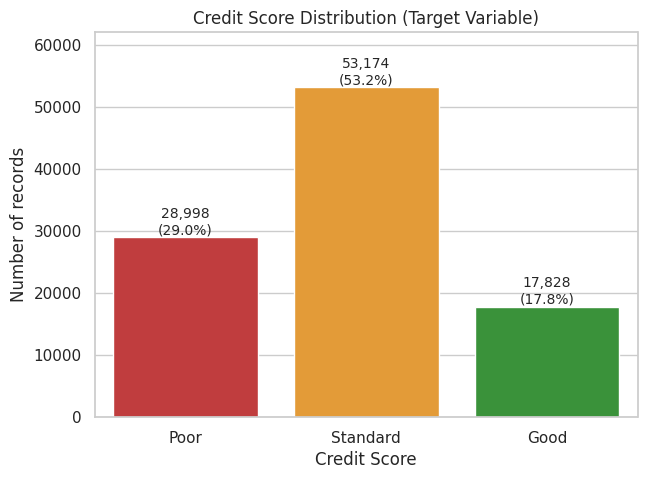

In [15]:
# Chart - 1 visualization code : distribution of the target variable
def annotate_bars(ax, total):
    """Write count and percentage on top of each bar."""
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(f"{int(h):,}\n({h/total:.1%})", (p.get_x() + p.get_width()/2, h),
                        ha="center", va="bottom", fontsize=10)

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=data, x="Credit_Score", order=SCORE_ORDER, palette=SCORE_COLORS, ax=ax)
annotate_bars(ax, len(data))
ax.set_title("Credit Score Distribution (Target Variable)")
ax.set_xlabel("Credit Score"); ax.set_ylabel("Number of records"); ax.set_ylim(0, 62000)
plt.show()

##### 1. Why did you pick the specific chart?

A **count plot with percentages** is the clearest way to show how a categorical target splits across classes.

##### 2. What is/are the insight(s) found from the chart?

Standard is the majority class (53.2%), then Poor (29.0%) and Good (17.8%). The target is moderately imbalanced.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it tells the business that most customers sit in the middle band, which is the biggest group to nurture toward Good through advice and product offers. **Negative / risk:** nearly 3 in 10 customers are Poor, a large pool of default risk; and because Good is the smallest class, a model trained naively would under-detect it, so class weights are used later.

#### Chart - 2 : Age Distribution

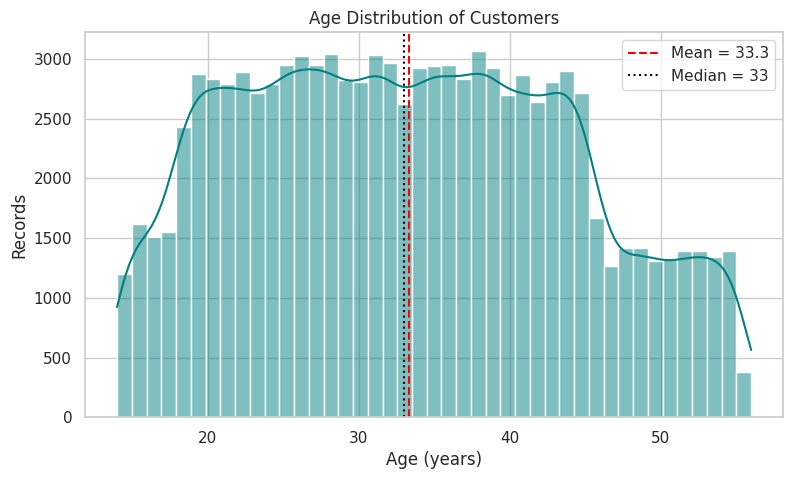

In [16]:
# Chart - 2 visualization code : age distribution
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data["Age"], bins=43, kde=True, color="teal", ax=ax)
ax.axvline(data["Age"].mean(), color="red", ls="--", label=f"Mean = {data['Age'].mean():.1f}")
ax.axvline(data["Age"].median(), color="black", ls=":", label=f"Median = {data['Age'].median():.0f}")
ax.set_title("Age Distribution of Customers"); ax.set_xlabel("Age (years)"); ax.set_ylabel("Records"); ax.legend()
plt.show()

##### 1. Why did you pick the specific chart?

A **histogram with KDE** shows the shape, spread and centre of a continuous variable such as age.

##### 2. What is/are the insight(s) found from the chart?

Customers are mostly young to middle-aged: the mean is about 33 and the median 33, with ages from 14 to 56 and no heavy skew. The age 14 minimum is unusual for a credit customer and worth validating.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the core audience is 25-45, so products and campaigns can be targeted at working-age customers. **Negative / risk:** very few older customers (50+) means limited insight there, and under-18 records may be data errors or compliance issues that need review.

#### Chart - 3 : Annual Income Distribution

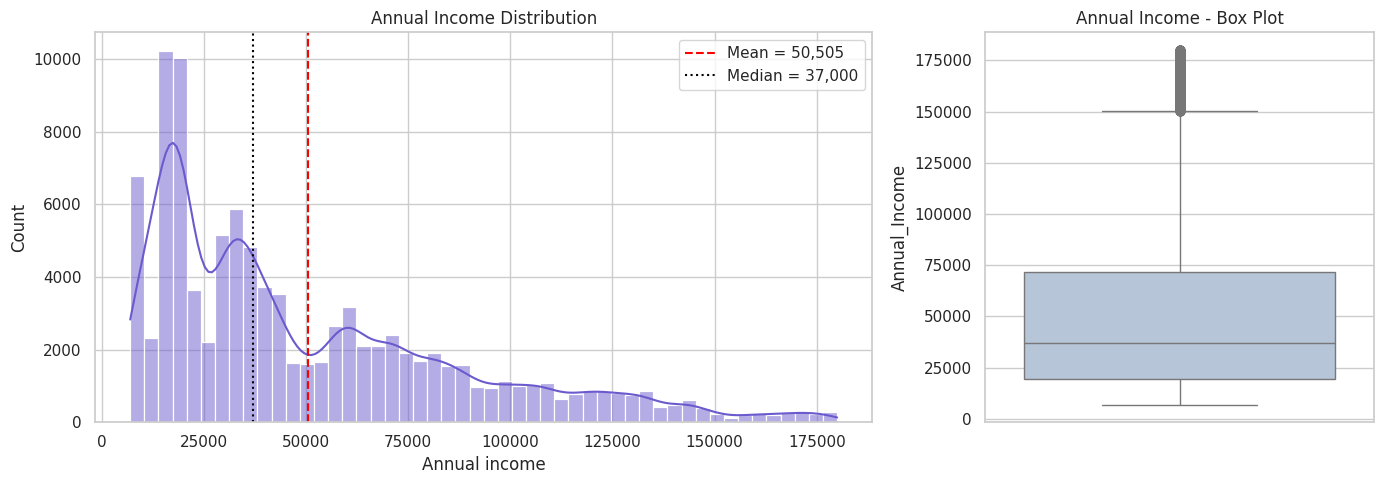

Skewness of Annual_Income: 1.13


In [17]:
# Chart - 3 visualization code : annual income distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(data["Annual_Income"], bins=50, kde=True, color="slateblue", ax=ax[0])
ax[0].axvline(data["Annual_Income"].mean(), color="red", ls="--", label=f"Mean = {data['Annual_Income'].mean():,.0f}")
ax[0].axvline(data["Annual_Income"].median(), color="black", ls=":", label=f"Median = {data['Annual_Income'].median():,.0f}")
ax[0].set_title("Annual Income Distribution"); ax[0].set_xlabel("Annual income"); ax[0].legend()
sns.boxplot(y=data["Annual_Income"], color="lightsteelblue", ax=ax[1])
ax[1].set_title("Annual Income - Box Plot")
plt.tight_layout(); plt.show()
print("Skewness of Annual_Income:", round(data["Annual_Income"].skew(), 2))

##### 1. Why did you pick the specific chart?

A **histogram plus box plot** together reveal skewness and outliers in income, which is important before modelling.

##### 2. What is/are the insight(s) found from the chart?

Income is right-skewed (skewness 1.13): the mean (about 50,500) is well above the median (about 37,000), and a long tail of high earners reaches about 180,000.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** most customers are low-to-middle income, which tells Paisabazaar where the volume is (small-ticket loans, credit-builder products). **Negative / risk:** averages overstate a typical customer's income, so pricing based on the mean would be wrong; the skew also justifies the log transformation and outlier capping later.

#### Chart - 4 : Occupation

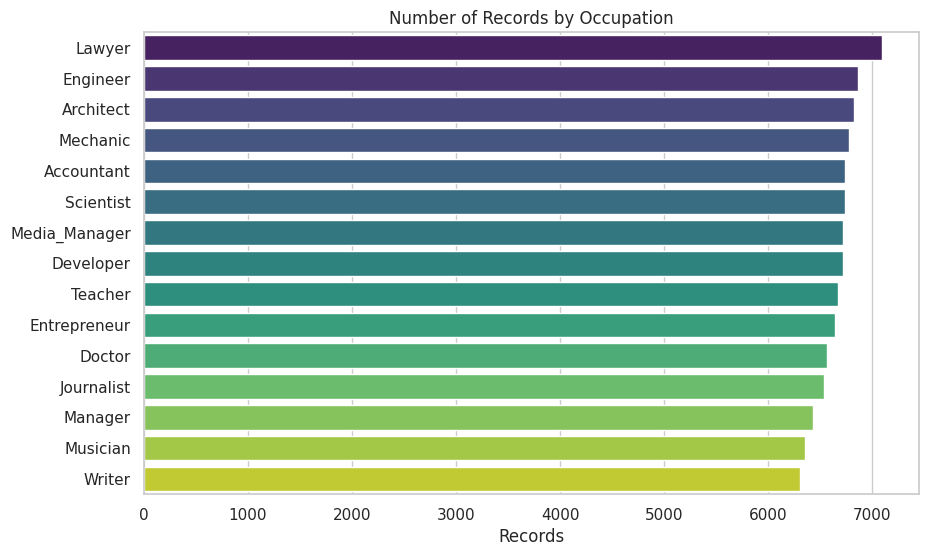

In [18]:
# Chart - 4 visualization code : occupation counts
order = data["Occupation"].value_counts().index
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=data, y="Occupation", order=order, palette="viridis", ax=ax)
ax.set_title("Number of Records by Occupation"); ax.set_xlabel("Records"); ax.set_ylabel("")
plt.show()

##### 1. Why did you pick the specific chart?

A **horizontal count plot** is easy to read when a categorical variable has many labels (15 occupations).

##### 2. What is/are the insight(s) found from the chart?

Occupations are almost evenly spread (about 6,300 to 7,100 records each). Lawyers and Engineers are slightly largest, with Writer, Musician and Manager at the lower end.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** no single profession dominates, so the customer base is diversified and not exposed to one industry. **Negative / risk:** none directly; but since the groups are so uniform, occupation will not help much in separating good and bad customers (confirmed in later charts).

#### Chart - 5 : Credit Mix & Payment Behaviour

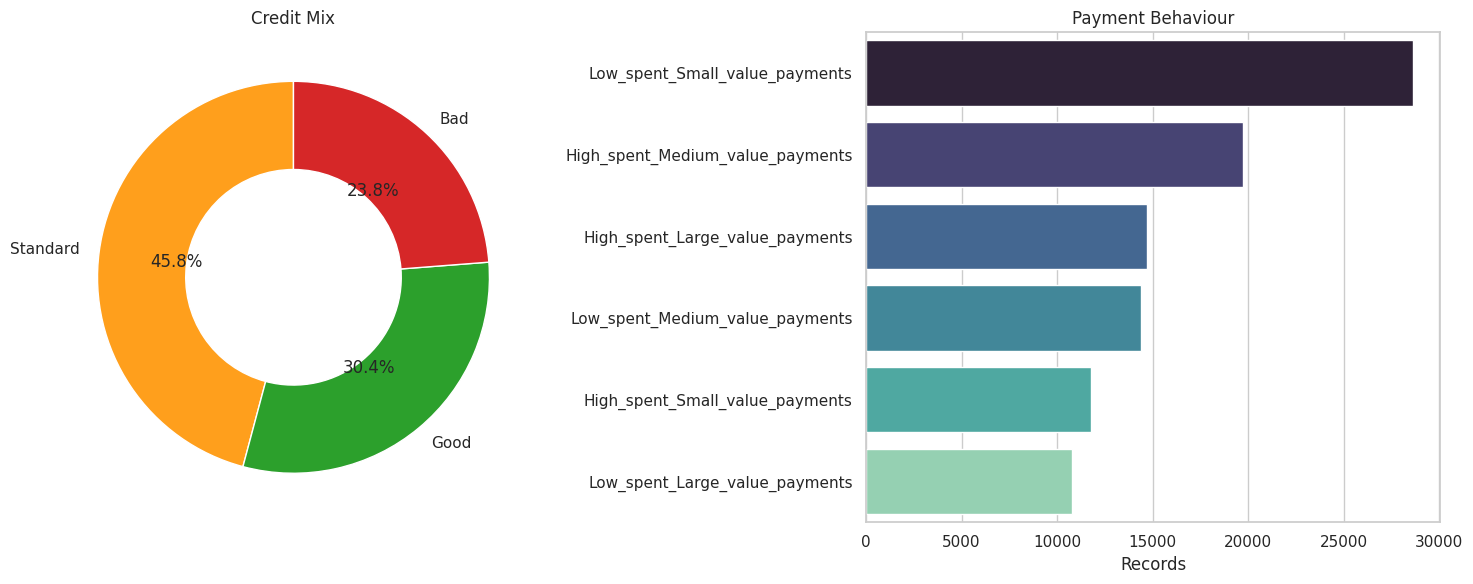

In [19]:
# Chart - 5 visualization code : credit mix and payment behaviour composition
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
mix = data["Credit_Mix"].value_counts()
ax[0].pie(mix, labels=mix.index, autopct="%1.1f%%", startangle=90, colors=["#ff9f1c", "#2ca02c", "#d62728"],
          wedgeprops={"width": 0.45})
ax[0].set_title("Credit Mix")
pb = data["Payment_Behaviour"].value_counts()
sns.barplot(x=pb.values, y=pb.index, palette="mako", ax=ax[1])
ax[1].set_title("Payment Behaviour"); ax[1].set_xlabel("Records"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A **donut chart** shows the share of each part of a whole for a variable with few categories (credit mix); a **bar chart** suits the 6-level payment behaviour.

##### 2. What is/are the insight(s) found from the chart?

Credit mix is Standard 45.8%, Good 30.4%, Bad 23.8%. The most common payment behaviour is *Low spent, Small value payments* (about 28.6%).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** almost a third of customers already have a Good mix, a ready audience for premium products. **Negative / risk:** about 24% have a Bad mix and the most common behaviour is low spending with small payments, which suggests many customers have limited repayment capacity.

### **BIVARIATE ANALYSIS (Categorical - Categorical)**

#### Chart - 6 : Credit Mix vs Credit Score

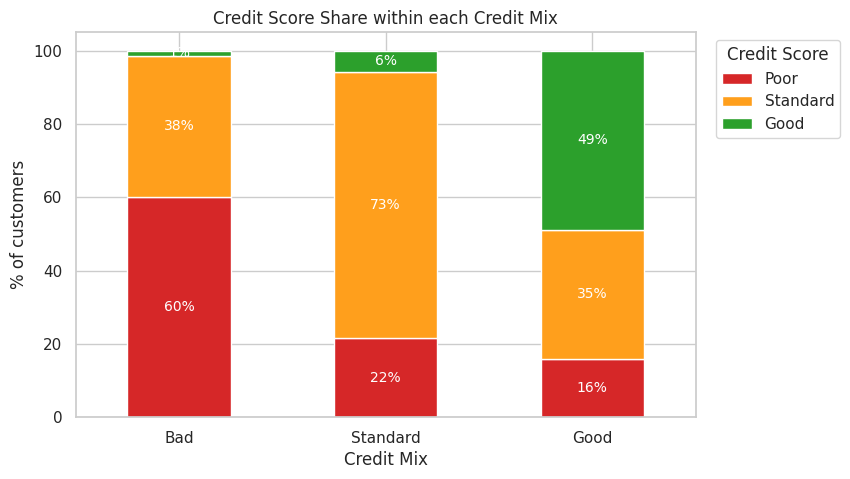

In [20]:
# Chart - 6 visualization code : Credit_Mix vs Credit_Score (categorical - categorical)
ct = pd.crosstab(data["Credit_Mix"], data["Credit_Score"], normalize="index")[SCORE_ORDER] * 100
ct = ct.loc[["Bad", "Standard", "Good"]]
ax = ct.plot(kind="bar", stacked=True, color=[SCORE_COLORS[s] for s in SCORE_ORDER], figsize=(8, 5))
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", label_type="center", color="white", fontsize=10)
ax.set_title("Credit Score Share within each Credit Mix"); ax.set_ylabel("% of customers"); ax.set_xlabel("Credit Mix")
plt.xticks(rotation=0); plt.legend(title="Credit Score", bbox_to_anchor=(1.02, 1))
plt.show()

##### 1. Why did you pick the specific chart?

A **100% stacked bar chart** compares the *proportion* of each score inside every credit-mix group, regardless of group size.

##### 2. What is/are the insight(s) found from the chart?

Credit mix and score are strongly linked: 60% of *Bad* mix customers are Poor and only 1.5% are Good; *Standard* mix customers are mostly Standard (73%); and 49% of *Good* mix customers are Good.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** credit mix is a very strong, easy-to-collect screening variable for quick risk triage. **Negative / risk:** customers with a Bad mix are over 30 times less likely to be Good than those with a Good mix, so approving them without extra safeguards raises default risk. Also, credit mix may be partly derived from the same behaviour as the score, so it should be used with care.

#### Chart - 7 : Minimum Payment Flag vs Credit Score

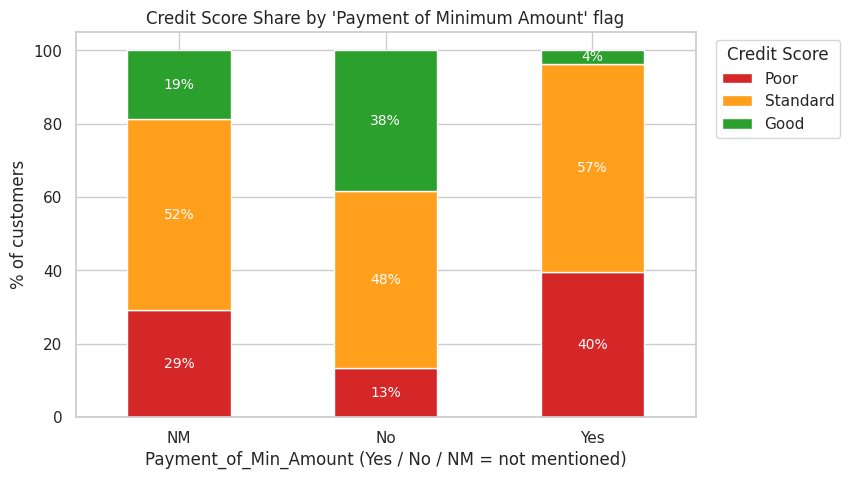

In [21]:
# Chart - 7 visualization code : Payment_of_Min_Amount vs Credit_Score (categorical - categorical)
ct = pd.crosstab(data["Payment_of_Min_Amount"], data["Credit_Score"], normalize="index")[SCORE_ORDER] * 100
ax = ct.plot(kind="bar", stacked=True, color=[SCORE_COLORS[s] for s in SCORE_ORDER], figsize=(8, 5))
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", label_type="center", color="white", fontsize=10)
ax.set_title("Credit Score Share by 'Payment of Minimum Amount' flag")
ax.set_ylabel("% of customers"); ax.set_xlabel("Payment_of_Min_Amount (Yes / No / NM = not mentioned)")
plt.xticks(rotation=0); plt.legend(title="Credit Score", bbox_to_anchor=(1.02, 1))
plt.show()

##### 1. Why did you pick the specific chart?

A **100% stacked bar chart** is again the best way to compare categorical-vs-categorical proportions.

##### 2. What is/are the insight(s) found from the chart?

The flag marks customers who pay only the minimum due. Customers flagged **Yes** are rarely Good (3.7%) and 39.6% are Poor; those flagged **No** are far better: 38.3% Good and only 13.4% Poor. 'NM' sits in between.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** paying only the minimum is a clear early-warning sign, so the business can send reminders or offer repayment plans to these customers before they slip. **Negative / risk:** more than half of the records (52%) are minimum-payers, meaning a big share of the book carries slow debt reduction and higher long-term default exposure.

### **BIVARIATE ANALYSIS (Numerical - Categorical)**

#### Chart - 8 : Income by Credit Score

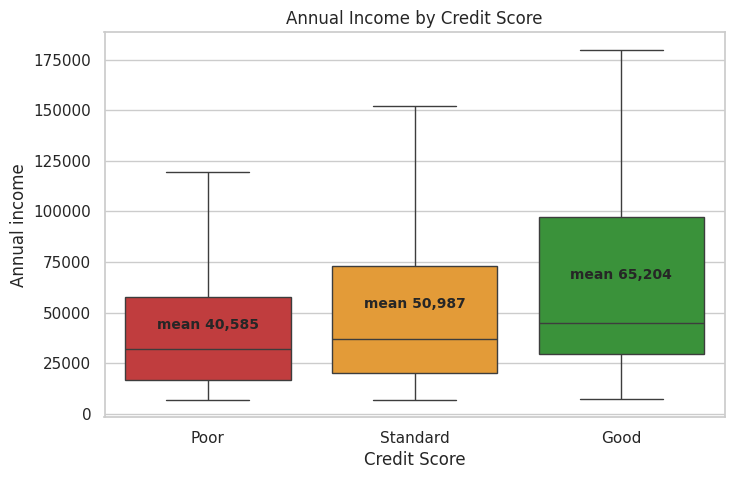

In [22]:
# Chart - 8 visualization code : Annual income by credit score (numerical - categorical)
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=data, x="Credit_Score", y="Annual_Income", order=SCORE_ORDER, palette=SCORE_COLORS, showfliers=False, ax=ax)
means = data.groupby("Credit_Score", observed=True)["Annual_Income"].mean()
for i, s in enumerate(SCORE_ORDER):
    ax.text(i, means[s], f"mean {means[s]:,.0f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_title("Annual Income by Credit Score"); ax.set_xlabel("Credit Score"); ax.set_ylabel("Annual income")
plt.show()

##### 1. Why did you pick the specific chart?

A **box plot** compares a numeric variable's distribution (median, spread, outliers) across the three score groups.

##### 2. What is/are the insight(s) found from the chart?

Income rises with credit score: mean of about 40,600 (Poor), 51,000 (Standard) and 65,200 (Good). The distributions overlap, so income helps but does not fully decide the score.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** higher-income customers are safer targets for larger loans and cards. **Negative / risk:** many low-income customers fall into Poor, so lending to them needs lower limits or collateral; however, income alone would wrongly reject good low-income customers because of the overlap.

#### Chart - 9 : Interest Rate by Credit Score

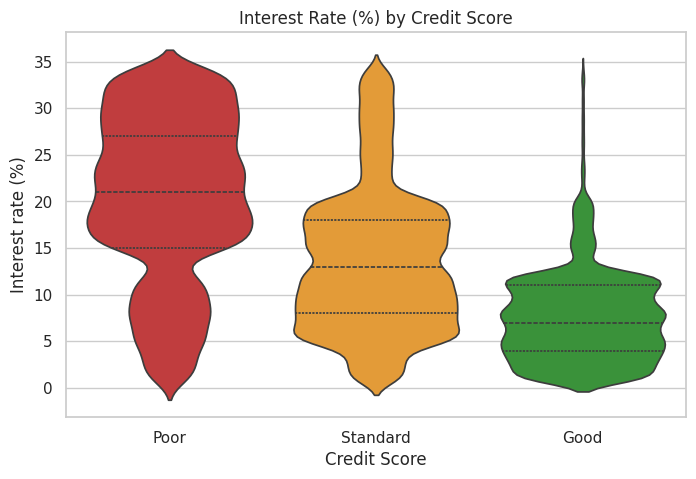

               mean  median
Credit_Score               
Poor          20.19    21.0
Standard      13.75    13.0
Good           7.66     7.0


In [23]:
# Chart - 9 visualization code : Interest rate by credit score (numerical - categorical)
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=data, x="Credit_Score", y="Interest_Rate", order=SCORE_ORDER, palette=SCORE_COLORS, inner="quartile", ax=ax)
ax.set_title("Interest Rate (%) by Credit Score"); ax.set_xlabel("Credit Score"); ax.set_ylabel("Interest rate (%)")
plt.show()
print(data.groupby("Credit_Score", observed=True)["Interest_Rate"].agg(["mean", "median"]).round(2))

##### 1. Why did you pick the specific chart?

A **violin plot** shows the full distribution shape *and* quartiles, which is useful when groups differ in both level and spread.

##### 2. What is/are the insight(s) found from the chart?

Interest rate separates the groups sharply: mean about 20.2% for Poor, 13.8% for Standard and 7.7% for Good, with little overlap between Poor and Good.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** this supports risk-based pricing, charging more for riskier customers to compensate for expected losses. **Negative / risk:** very high rates (above 20%) fall on the customers who can least afford them, which can worsen repayment problems and customer satisfaction, creating a self-reinforcing cycle of Poor scores.

#### Chart - 10 : Payment Delay by Credit Score

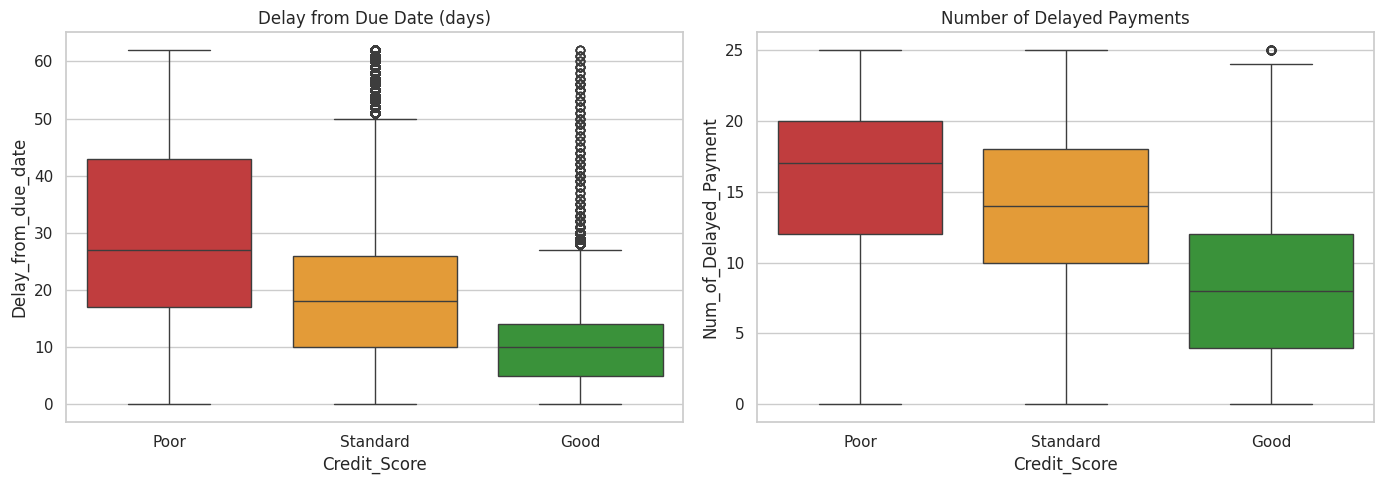

In [24]:
# Chart - 10 visualization code : payment delay by credit score (numerical - categorical)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=data, x="Credit_Score", y="Delay_from_due_date", order=SCORE_ORDER, palette=SCORE_COLORS, ax=ax[0])
ax[0].set_title("Delay from Due Date (days)")
sns.boxplot(data=data, x="Credit_Score", y="Num_of_Delayed_Payment", order=SCORE_ORDER, palette=SCORE_COLORS, ax=ax[1])
ax[1].set_title("Number of Delayed Payments")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

**Box plots** side by side show both the typical value and the extreme cases for payment delay measures.

##### 2. What is/are the insight(s) found from the chart?

Delays grow steeply as score falls: average delay is about 11 days (Good), 20 days (Standard) and 30 days (Poor); the number of delayed payments is 8.6, 13.5 and 15.8 respectively. Poor customers also have a long tail up to 60 days.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** payment delay is a clear, measurable early indicator, so a delay-triggered alert system can identify at-risk customers early. **Negative / risk:** long delays (30 to 60 days) mean cash-flow loss and a high probability of default; the longer a customer is late, the worse the loss.

#### Chart - 11 : Loans & Debt by Credit Score

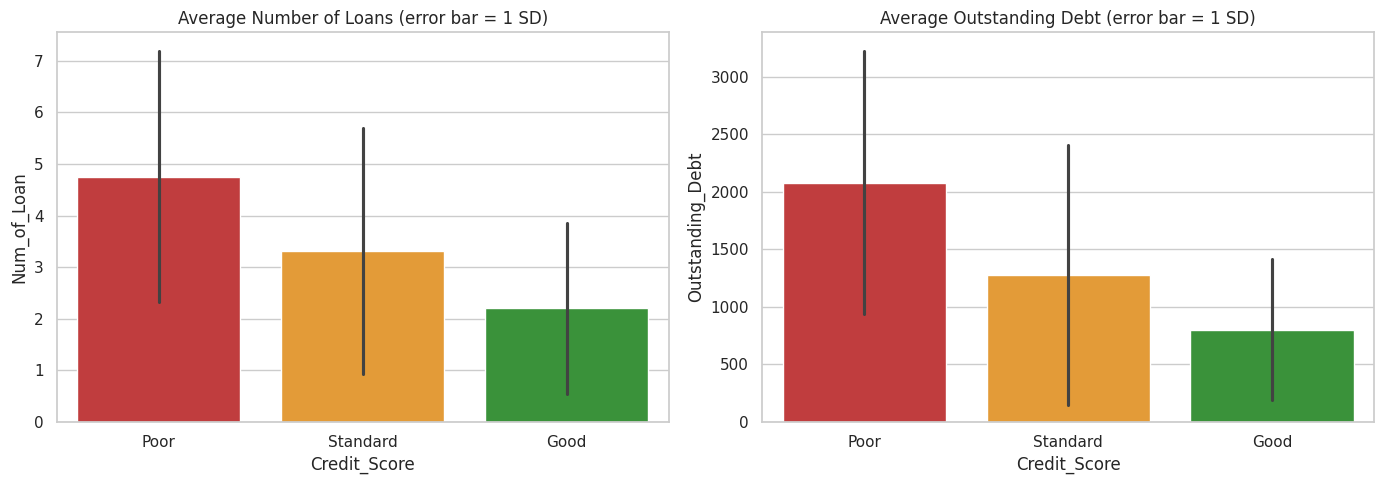

              Num_of_Loan  Outstanding_Debt
Credit_Score                               
Poor                  4.8            2081.5
Standard              3.3            1278.4
Good                  2.2             801.3


In [25]:
# Chart - 11 visualization code : number of loans and outstanding debt by credit score
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=data, x="Credit_Score", y="Num_of_Loan", order=SCORE_ORDER, palette=SCORE_COLORS, errorbar="sd", ax=ax[0])
ax[0].set_title("Average Number of Loans (error bar = 1 SD)")
sns.barplot(data=data, x="Credit_Score", y="Outstanding_Debt", order=SCORE_ORDER, palette=SCORE_COLORS, errorbar="sd", ax=ax[1])
ax[1].set_title("Average Outstanding Debt (error bar = 1 SD)")
plt.tight_layout(); plt.show()
print(data.groupby("Credit_Score", observed=True)[["Num_of_Loan", "Outstanding_Debt"]].mean().round(1))

##### 1. Why did you pick the specific chart?

**Bar charts with error bars** compare the mean of two numeric variables per group and show how much they vary.

##### 2. What is/are the insight(s) found from the chart?

Poor customers hold about 4.8 loans on average vs 3.3 (Standard) and 2.2 (Good), and their outstanding debt is about 2,081 vs 1,278 and 801. The wide error bars show the Poor group is also much more varied.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** loan count and debt are good early warning variables, and they support a rule such as capping new credit above a certain number of loans. **Negative / risk:** customers with 5+ loans and high debt are over-leveraged; giving them more credit increases the risk of default.

### **BIVARIATE ANALYSIS (Numerical - Numerical)**

#### Chart - 12 : Income vs Monthly Investment

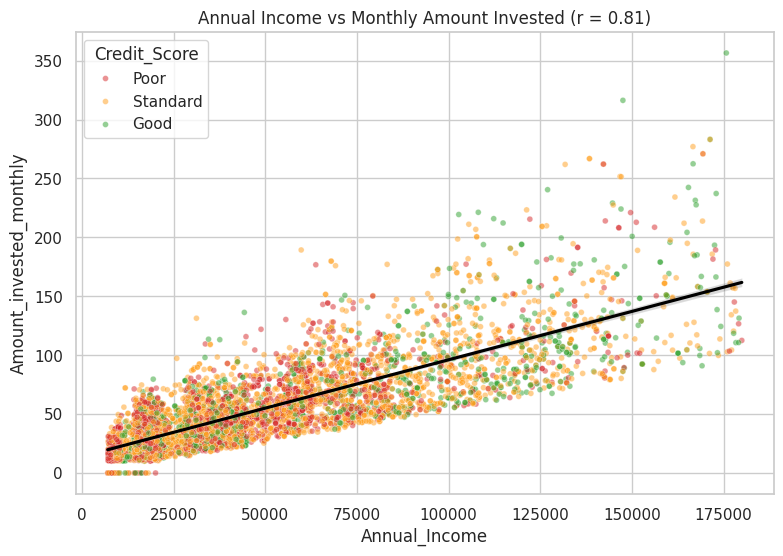

In [26]:
# Chart - 12 visualization code : income vs monthly investment (numerical - numerical)
sample = data.sample(6000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=sample, x="Annual_Income", y="Amount_invested_monthly", hue="Credit_Score",
                hue_order=SCORE_ORDER, palette=SCORE_COLORS, alpha=0.5, s=18, ax=ax)
sns.regplot(data=sample, x="Annual_Income", y="Amount_invested_monthly", scatter=False, color="black", ax=ax)
r = data["Annual_Income"].corr(data["Amount_invested_monthly"])
ax.set_title(f"Annual Income vs Monthly Amount Invested (r = {r:.2f})")
plt.show()

##### 1. Why did you pick the specific chart?

A **scatter plot with regression line** shows the relationship between two numeric variables, and colour adds the credit score.

##### 2. What is/are the insight(s) found from the chart?

Income and monthly investment are strongly positively related (r = 0.81): richer customers invest more. Good-score points cluster in the high-income, high-investment region, while Poor points sit near the bottom-left.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** high-income customers with a high investment amount are ideal for cross-selling investment and wealth products. **Negative / risk:** low-income customers invest very little, so they have no financial buffer and are vulnerable to shocks, which increases the chance of missed payments.

### **MULTIVARIATE ANALYSIS**

#### Chart - 13 : Credit History vs Debt (Multivariate)

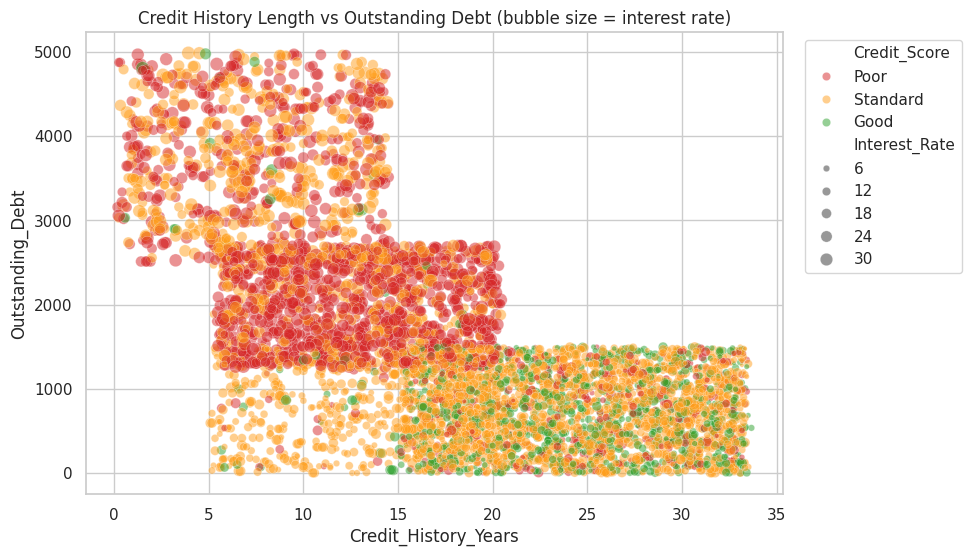

Correlation (history vs debt): -0.63


In [27]:
# Chart - 13 visualization code : credit history vs outstanding debt, split by score (multivariate)
sample = data.sample(6000, random_state=RANDOM_STATE)   # plotting sample
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=sample, x="Credit_History_Years", y="Outstanding_Debt", hue="Credit_Score",
                hue_order=SCORE_ORDER, palette=SCORE_COLORS, size="Interest_Rate", sizes=(10, 90), alpha=0.5, ax=ax)
ax.set_title("Credit History Length vs Outstanding Debt (bubble size = interest rate)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()
print("Correlation (history vs debt):", round(data["Credit_History_Years"].corr(data["Outstanding_Debt"]), 2))

##### 1. Why did you pick the specific chart?

A **coloured scatter plot with bubble size** compares three or four variables at once (history length, debt, score and interest rate), which makes it a multivariate view.

##### 2. What is/are the insight(s) found from the chart?

Longer credit history goes with lower debt (r = -0.63). Poor customers (red) are concentrated in the short-history, high-debt zone, and they also carry the larger bubbles (higher interest rates). Good customers sit in the long-history, low-debt zone.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** length of history is a strong trust signal, so established customers can be offered better terms to retain them. **Negative / risk:** new-to-credit customers with a short history are riskier and harder to evaluate; rejecting all of them would lose potential good customers, so they need careful alternatives (e.g. credit-builder loans with small limits).

#### Chart - 14 - Correlation Heatmap

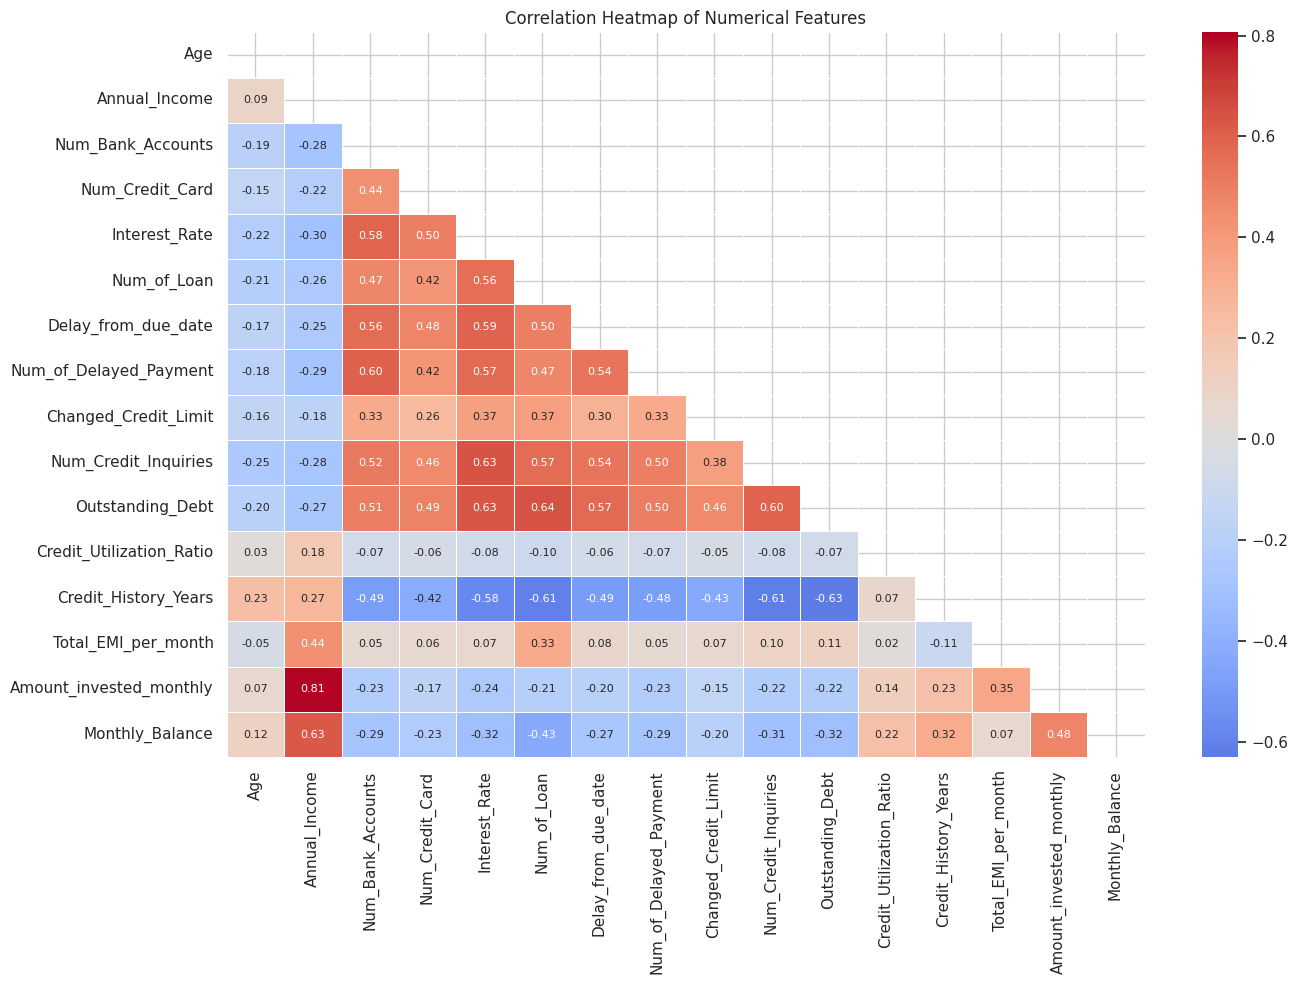

In [28]:
# Correlation Heatmap visualization code
num_cols = ["Age", "Annual_Income", "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate", "Num_of_Loan",
            "Delay_from_due_date", "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Num_Credit_Inquiries",
            "Outstanding_Debt", "Credit_Utilization_Ratio", "Credit_History_Years", "Total_EMI_per_month",
            "Amount_invested_monthly", "Monthly_Balance"]
corr = data[num_cols].corr()
fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=np.triu(np.ones_like(corr, dtype=bool)),
            linewidths=0.5, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation Heatmap of Numerical Features")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A **correlation heatmap** quickly summarises all pairwise linear relationships between numeric features and is key for spotting multicollinearity.

##### 2. What is/are the insight(s) found from the chart?

Interest rate, number of delayed payments, delay days, bank accounts, number of loans, inquiries and outstanding debt are all positively correlated with each other (about 0.5 to 0.64), while credit history is negatively correlated with them (about -0.5 to -0.63). Annual income and monthly salary are almost identical (1.00) and income is strongly related to investment (0.81). Credit utilisation is hardly related to anything (|r| < 0.25).

#### Chart - 15 - Pair Plot

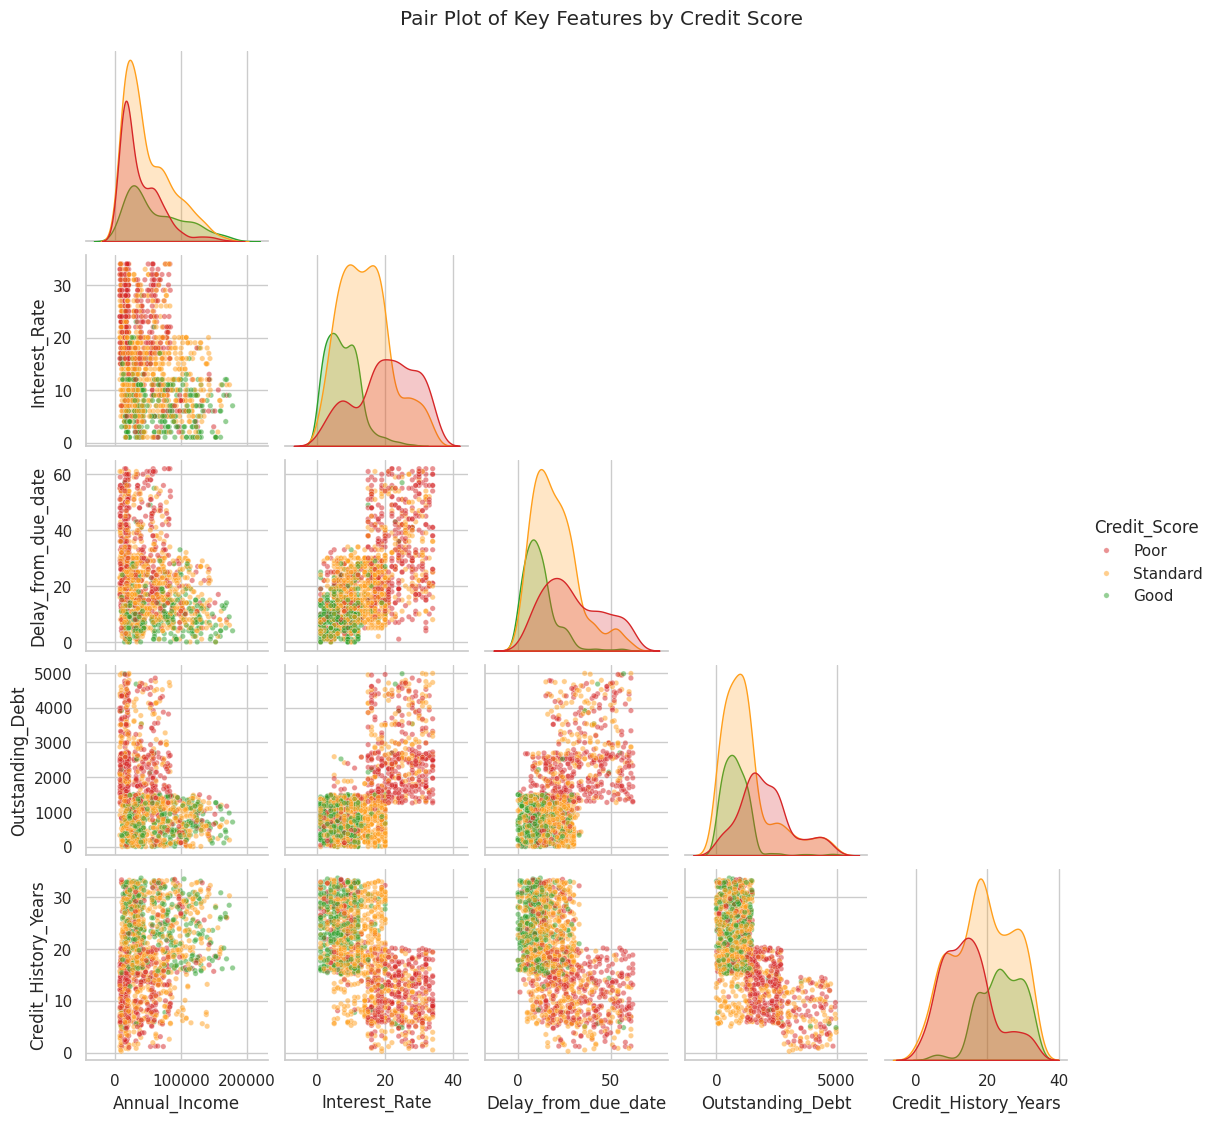

In [29]:
# Pair Plot visualization code
pair_cols = ["Annual_Income", "Interest_Rate", "Delay_from_due_date", "Outstanding_Debt", "Credit_History_Years"]
pp_sample = data.sample(1500, random_state=RANDOM_STATE)
g = sns.pairplot(pp_sample, vars=pair_cols, hue="Credit_Score", hue_order=SCORE_ORDER, palette=SCORE_COLORS,
                 corner=True, plot_kws={"alpha": 0.5, "s": 15}, height=2.2)
g.fig.suptitle("Pair Plot of Key Features by Credit Score", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A **pair plot** shows every pairwise scatter and the per-class distributions together, which is ideal for seeing how well the score groups separate.

##### 2. What is/are the insight(s) found from the chart?

The classes separate visibly: Poor customers form a cluster at high interest rate (above about 20%), long delays and high debt, while Good customers sit at low interest, short delay and long history. Standard sits in between and overlaps with both, which explains why Standard is the hardest class to predict.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the charts, three hypotheses are tested (significance level alpha = 0.05):
1. Customers with a Good score earn more than customers with a Poor score (Chart 8).
2. Credit score depends on credit mix (Chart 6).
3. Outstanding debt differs across the three credit-score groups (Chart 11).

*Note:* each customer appears in 8 monthly rows, so rows are not fully independent; with this much data, p-values are extremely small, so the effect sizes (e.g. Cramer's V) matter as much as the p-values.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** The income of Good-score customers is **less than or equal to** that of Poor-score customers.

**H1:** The income of Good-score customers is **greater** than that of Poor-score customers.

#### 2. Perform an appropriate statistical test.

In [30]:
# Hypothesis 1 : Annual income of 'Good' vs 'Poor' score customers
good_inc = data.loc[data["Credit_Score"] == "Good", "Annual_Income"]
poor_inc = data.loc[data["Credit_Score"] == "Poor", "Annual_Income"]

# Normality check first (sample, because Shapiro is limited to ~5000 points)
print("Shapiro p-value (Good, n=2000):", stats.shapiro(good_inc.sample(2000, random_state=1)).pvalue)
print("Shapiro p-value (Poor, n=2000):", stats.shapiro(poor_inc.sample(2000, random_state=1)).pvalue)

u_stat, p_val = stats.mannwhitneyu(good_inc, poor_inc, alternative="greater")
print(f"\nMann-Whitney U = {u_stat:,.0f}, p-value = {p_val:.3e}")
print("Reject H0" if p_val < 0.05 else "Fail to reject H0", "(alpha = 0.05)")

Shapiro p-value (Good, n=2000): 4.332581183002682e-33
Shapiro p-value (Poor, n=2000): 4.054572403100288e-40

Mann-Whitney U = 349,453,179, p-value = 0.000e+00
Reject H0 (alpha = 0.05)


##### Which statistical test have you done to obtain P-Value?

**Mann-Whitney U test** (one-sided). The result is U = 349,453,179 with p-value approximately 0 (below 1e-300), so **H0 is rejected**: Good-score customers earn significantly more than Poor-score customers.

##### Why did you choose the specific statistical test?

Income is clearly not normally distributed (the Shapiro-Wilk p-values are about 1e-33 and 1e-40) and it is right-skewed, so the non-parametric Mann-Whitney U test is more appropriate than a t-test. It compares two independent groups without assuming normality.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** Credit score and credit mix are **independent** (no association).

**H1:** Credit score and credit mix are **associated**.

#### 2. Perform an appropriate statistical test.

In [31]:
# Hypothesis 2 : Credit_Score is independent of Credit_Mix
contingency = pd.crosstab(data["Credit_Mix"], data["Credit_Score"])
chi2, p_val, dof, _ = stats.chi2_contingency(contingency)
cramers_v = np.sqrt(chi2 / (contingency.values.sum() * (min(contingency.shape) - 1)))
print(f"Chi-square = {chi2:,.1f}, dof = {dof}, p-value = {p_val:.3e}, Cramer's V = {cramers_v:.2f}")
print("Reject H0" if p_val < 0.05 else "Fail to reject H0", "(alpha = 0.05)")

Chi-square = 40,489.4, dof = 4, p-value = 0.000e+00, Cramer's V = 0.45
Reject H0 (alpha = 0.05)


##### Which statistical test have you done to obtain P-Value?

**Chi-square test of independence.** The result is chi-square = 40,489 with 4 degrees of freedom, p-value approximately 0, so **H0 is rejected**. Cramer's V = 0.45 indicates a strong association, not just a statistically significant one.

##### Why did you choose the specific statistical test?

Both variables are categorical, and the chi-square test of independence is the standard test for association between two categorical variables. Cramer's V is added to measure the strength of the relationship.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** Mean outstanding debt is the **same** across Poor, Standard and Good groups.

**H1:** At least one group has a **different** outstanding debt.

#### 2. Perform an appropriate statistical test.

In [32]:
# Hypothesis 3 : Outstanding debt differs across the three credit-score groups
groups = [g["Outstanding_Debt"].values for _, g in data.groupby("Credit_Score", observed=True)]
h_stat, p_val = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {h_stat:,.1f}, p-value = {p_val:.3e}")
print("Reject H0" if p_val < 0.05 else "Fail to reject H0", "(alpha = 0.05)")

# Post-hoc: which pairs differ? (Mann-Whitney with Bonferroni correction for 3 comparisons)
pairs = [("Poor", "Standard"), ("Standard", "Good"), ("Poor", "Good")]
for a, b in pairs:
    ga = data.loc[data["Credit_Score"] == a, "Outstanding_Debt"]; gb = data.loc[data["Credit_Score"] == b, "Outstanding_Debt"]
    p = min(stats.mannwhitneyu(ga, gb).pvalue * 3, 1.0)
    print(f"  {a:9s} vs {b:9s}: adjusted p = {p:.2e}")

Kruskal-Wallis H = 19,399.6, p-value = 0.000e+00
Reject H0 (alpha = 0.05)
  Poor      vs Standard : adjusted p = 0.00e+00
  Standard  vs Good     : adjusted p = 0.00e+00
  Poor      vs Good     : adjusted p = 0.00e+00


##### Which statistical test have you done to obtain P-Value?

**Kruskal-Wallis H test** with pairwise Mann-Whitney post-hoc tests (Bonferroni corrected). H = 19,400 and p approximately 0, so **H0 is rejected**, and every pair (Poor-Standard, Standard-Good, Poor-Good) differs significantly.

##### Why did you choose the specific statistical test?

There are three independent groups and debt is skewed (not normal), so the non-parametric alternative to one-way ANOVA, Kruskal-Wallis, is used. The post-hoc tests with Bonferroni correction show which groups differ while controlling for multiple comparisons.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [33]:
# Handling Missing Values & Missing Value Imputation
print("Missing values before imputation:", data.isnull().sum().sum())

# The only 'hidden' missing information is the 'NM' (not mentioned) flag: we keep it as its own category
# because it is informative (see Chart 7) instead of guessing Yes/No.
print(data["Payment_of_Min_Amount"].value_counts())

# Safety net so the pipeline never fails on future data: median for numbers, mode for categories
for col in data.select_dtypes("number").columns:
    data[col] = data[col].fillna(data[col].median())
for col in data.select_dtypes("object").columns:
    data[col] = data[col].fillna(data[col].mode()[0])
print("Missing values after imputation :", data.isnull().sum().sum())

Missing values before imputation: 0
Payment_of_Min_Amount
Yes    52326
No     35667
NM     12007
Name: count, dtype: int64
Missing values after imputation : 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

No true NaN values exist, so no rows were removed or filled. The 'NM' value of `Payment_of_Min_Amount` was kept as a separate category (it behaves differently from both Yes and No in Chart 7), and 'No Data' loan types correspond to customers with zero loans, so they were mapped to a loan count of 0. A median / mode imputation step is included as a safety net so that the notebook still works if new data contains gaps.

### 2. Handling Outliers

In [34]:
# Handling Outliers & Outlier treatments
def cap_outliers_iqr(frame, columns, factor=1.5):
    """Winsorise columns at Q1 - factor*IQR and Q3 + factor*IQR; return the report of capped rows."""
    report = {}
    for col in columns:
        q1, q3 = frame[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - factor * iqr, q3 + factor * iqr
        report[col] = int(((frame[col] < low) | (frame[col] > high)).sum())
        frame[col] = frame[col].clip(low, high)
    return pd.Series(report, name="rows_capped")

skewed_cols = ["Annual_Income", "Monthly_Inhand_Salary", "Total_EMI_per_month", "Amount_invested_monthly",
               "Monthly_Balance", "Debt_to_Income", "EMI_to_Salary", "Savings_Ratio"]
cap_report = cap_outliers_iqr(data, skewed_cols)
cap_report.to_frame()

,rows_capped
Annual_Income,2000
Monthly_Inhand_Salary,2017
Total_EMI_per_month,5044
Amount_invested_monthly,4464
Monthly_Balance,7400
Debt_to_Income,10496
EMI_to_Salary,3500
Savings_Ratio,4891


##### What all outlier treatment techniques have you used and why did you use those techniques?

**IQR winsorisation (capping)** at Q1 - 1.5xIQR and Q3 + 1.5xIQR was applied to the skewed money columns (income, salary, EMI, investment, balance and the ratio features). Capping keeps all 100,000 rows (customers with extreme values are not deleted) while stopping extreme values from dominating the scaling and the linear model. Count variables and bounded variables (e.g. interest rate, utilisation) were left untouched because their extreme values are genuine.

### 3. Categorical Encoding

In [35]:
# Encode your categorical columns
# 1. Ordinal encoding: Credit_Mix has a natural order Bad < Standard < Good
data["Credit_Mix_Encoded"] = data["Credit_Mix"].map({"Bad": 0, "Standard": 1, "Good": 2})

# 2. Target encoding: Poor=0, Standard=1, Good=2
data["Target"] = data["Credit_Score"].map({"Poor": 0, "Standard": 1, "Good": 2}).astype(int)

# 3. One-hot encoding for nominal columns is done inside the model pipeline (prevents leakage)
nominal_cols = ["Occupation", "Payment_of_Min_Amount", "Payment_Behaviour"]
print("Nominal columns to one-hot encode:", nominal_cols)
data[["Credit_Mix", "Credit_Mix_Encoded", "Credit_Score", "Target"]].drop_duplicates().sort_values("Target").head(9)

Nominal columns to one-hot encode: ['Occupation', 'Payment_of_Min_Amount', 'Payment_Behaviour']


,Credit_Mix,Credit_Mix_Encoded,Credit_Score,Target
56,Standard,1,Poor,0
152,Bad,0,Poor,0
712,Good,2,Poor,0
32,Standard,1,Standard,1
155,Bad,0,Standard,1
7,Good,2,Standard,1
147,Standard,1,Good,2
0,Good,2,Good,2
686,Bad,0,Good,2


#### What all categorical encoding techniques have you used & why did you use those techniques?

**Ordinal encoding** for `Credit_Mix` (Bad = 0, Standard = 1, Good = 2) because it has a natural order, and the same for the target (Poor = 0, Standard = 1, Good = 2). **One-hot encoding** for the nominal columns `Occupation`, `Payment_of_Min_Amount`, `Payment_Behaviour` (no natural order), which is done inside the model pipeline so that the encoder is fitted on the training data only.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

This is a structured (tabular) dataset, so NLP text preprocessing is **not applicable**. The only free-text column, `Type_of_Loan`, was converted to a numeric loan-type count in the Data Wrangling section.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation & 2. Feature Selection

In [36]:
# Manipulate Features to minimize feature correlation and create new features
# Monthly_Inhand_Salary is (almost) Annual_Income / 12 (correlation = 1.00) -> keep only one of them.
print("Corr(Annual_Income, Monthly_Inhand_Salary):", round(data["Annual_Income"].corr(data["Monthly_Inhand_Salary"]), 3))

# Select features wisely to avoid overfitting
drop_cols = ["Customer_ID", "Month", "Type_of_Loan", "Credit_Score", "Credit_Mix",
             "Monthly_Inhand_Salary",         # duplicate of Annual_Income
             "Credit_History_Age"]            # duplicate of Credit_History_Years (months vs years)
numeric_features = [c for c in data.columns if c not in drop_cols + ["Target"] + nominal_cols]
features = numeric_features + nominal_cols
print(f"\n{len(features)} features selected:")
print(features)

Corr(Annual_Income, Monthly_Inhand_Salary): 0.998

24 features selected:
['Age', 'Annual_Income', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance', 'Credit_History_Years', 'Loan_Types_Count', 'Debt_to_Income', 'EMI_to_Salary', 'Savings_Ratio', 'Credit_Mix_Encoded', 'Occupation', 'Payment_of_Min_Amount', 'Payment_Behaviour']


##### What all feature selection methods have you used  and why?

**Methods:** (1) correlation analysis to remove redundant columns (`Monthly_Inhand_Salary` duplicates `Annual_Income`; `Credit_History_Age` duplicates `Credit_History_Years`), (2) removing identifiers and text with no signal (`Customer_ID`, `Month`, `Type_of_Loan` after converting it to a count), and (3) permutation importance after modelling to confirm what the model really uses.

The 24 features kept are listed in the output above.

##### Which all features you found important and why?

From permutation importance (see Section 7): **Credit Mix** (largest by a wide margin), **Interest Rate**, **Delay from due date**, **Outstanding Debt** and **Credit History length**. They are important because they directly measure repayment discipline, debt burden and track record, the same things a lender uses to judge risk. They match the EDA, where these same variables separated the three score groups most clearly.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [37]:
# Transform Your data
# Income / debt / EMI are right-skewed. A log transform suits income, but it over-corrects debt and EMI
# (skew flips to strongly negative), so a milder square-root transform is used for those two.
skew_cols = ["Annual_Income", "Outstanding_Debt", "Total_EMI_per_month"]
skew_before = data[skew_cols].skew()

data["Annual_Income"]        = np.log1p(data["Annual_Income"])
data["Outstanding_Debt"]     = np.sqrt(data["Outstanding_Debt"])
data["Total_EMI_per_month"]  = np.sqrt(data["Total_EMI_per_month"])

skew_after = data[skew_cols].skew()
pd.DataFrame({"skew_before": skew_before, "skew_after": skew_after,
              "transform": ["log1p", "sqrt", "sqrt"]}, index=skew_cols).round(2)

,skew_before,skew_after,transform
Annual_Income,1.02,-0.09,log1p
Outstanding_Debt,1.21,0.31,sqrt
Total_EMI_per_month,1.08,0.10,sqrt


Yes. Income, outstanding debt and EMI were right-skewed. **log(1+x)** was used for income (skewness 1.02 to -0.09), and the milder **square-root** for outstanding debt (1.21 to 0.31) and EMI (1.08 to 0.10); log over-corrected those two. This makes the distributions more symmetric, which helps Logistic Regression and does no harm to the tree models.

### 6. Data Scaling

In [38]:
# Scaling your data
# Scaling is done inside the pipeline (fit on train only -> no data leakage)
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), nominal_cols),
])
print("Preprocessor ready:", preprocessor)

Preprocessor ready: ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Age', 'Annual_Income', 'Num_Bank_Accounts',
                                  'Num_Credit_Card', 'Interest_Rate',
                                  'Num_of_Loan', 'Delay_from_due_date',
                                  'Num_of_Delayed_Payment',
                                  'Changed_Credit_Limit',
                                  'Num_Credit_Inquiries', 'Outstanding_Debt',
                                  'Credit_Utilization_Ratio',
                                  'Total_EMI_per_month',
                                  'Amount_invested_monthly', 'Monthly_Balance',
                                  'Credit_History_Years', 'Loan_Types_Count',
                                  'Debt_to_Income', 'EMI_to_Salary',
                                  'Savings_Ratio', 'Credit_Mix_Encoded']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
    

##### Which method have you used to scale you data and why?

**StandardScaler** (zero mean, unit variance) on all numeric features, because Logistic Regression is sensitive to feature scale and mixing income-scale and ratio-scale variables would distort it. It is fitted inside the pipeline on training data only, so no information from the test set leaks in.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No. There are only 24 features and 80,000 training rows, so there is no curse-of-dimensionality problem. PCA would also make the features harder to explain to the business.

In [39]:
# DImensionality Reduction (If needed)
print(f"Feature count: {len(features)} (numeric: {len(numeric_features)}, categorical: {len(nominal_cols)})")
print("-> No PCA applied; feature count is small relative to 100,000 rows.")

Feature count: 24 (numeric: 21, categorical: 3)
-> No PCA applied; feature count is small relative to 100,000 rows.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Not applicable: no dimensionality reduction was used, in order to keep the model explainable.

### 8. Data Splitting

In [40]:
# Split your data to train and test. Choose Splitting ratio wisely.
# Each customer appears in 8 monthly rows -> split BY CUSTOMER so that the same person is never in both sets.
X, y, groups = data[features], data["Target"], data["Customer_ID"]
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Customers shared between train and test:", len(set(g_train) & set(groups.iloc[test_idx])))

Train: (80000, 24)  Test: (20000, 24)
Customers shared between train and test: 0


##### What data splitting ratio have you used and why?

**80% train / 20% test, split by customer** (`GroupShuffleSplit`). Because each customer has 8 rows with near-identical attributes, a random row split would put the same customer in both sets and give an over-optimistic score. Splitting by customer (0 customers shared) gives an honest estimate for *new* customers. 80/20 leaves plenty of training data and a test set of 20,000 rows, large enough for stable metrics.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Moderately: Standard is 53.2%, Poor 29.0% and Good 17.8%. Good (the smallest class) could be under-predicted by a model that simply maximises accuracy.

In [41]:
# Handling Imbalanced Dataset (If needed)
print("Class share in training data:")
print((y_train.value_counts(normalize=True).sort_index().rename({0: "Poor", 1: "Standard", 2: "Good"}) * 100).round(1))
# class_weight="balanced" is passed to the models below (no synthetic rows are created)

Class share in training data:
Target
Poor        29.0
Standard    53.2
Good        17.8
Name: proportion, dtype: float64


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

**Class weights (`class_weight='balanced'`)**: it penalises mistakes on the minority classes more, without creating synthetic rows (as SMOTE would) or discarding data. It is simple, leak-free and works inside the pipeline, and the ratio is only moderate, so heavy resampling is not needed.

## ***7. ML Model Implementation***

### Helper functions

In [42]:
# Helper functions (reused by every model -> modular, DRY code)
LABELS = ["Poor", "Standard", "Good"]
results = {}          # collects metrics of every model for the final comparison

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, show=True):
    """Fit the model, predict on the test set, store and plot the evaluation metrics."""
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    metrics = {
        "Accuracy":        accuracy_score(y_te, pred),
        "Precision (macro)": precision_score(y_te, pred, average="macro"),
        "Recall (macro)":  recall_score(y_te, pred, average="macro"),
        "F1 (macro)":      f1_score(y_te, pred, average="macro"),
    }
    results[name] = metrics
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
        pd.Series(metrics).plot(kind="bar", ax=ax[0], color="steelblue", ylim=(0, 1))
        for c in ax[0].containers:
            ax[0].bar_label(c, fmt="%.3f")
        ax[0].set_title(f"{name} - Evaluation Metric Scores"); ax[0].tick_params(axis="x", rotation=20)
        ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=LABELS).plot(ax=ax[1], cmap="Blues", colorbar=False)
        ax[1].set_title(f"{name} - Confusion Matrix")
        plt.tight_layout(); plt.show()
        print(classification_report(y_te, pred, target_names=LABELS, digits=3))
    return model, metrics

def make_pipeline(estimator):
    """Preprocessing + estimator in a single object (safe against leakage, easy to save)."""
    return Pipeline([("prep", preprocessor), ("model", estimator)])

cv = GroupKFold(n_splits=3)   # group-aware cross-validation (same customer never split across folds)

### ML Model - 1 : Logistic Regression (baseline)

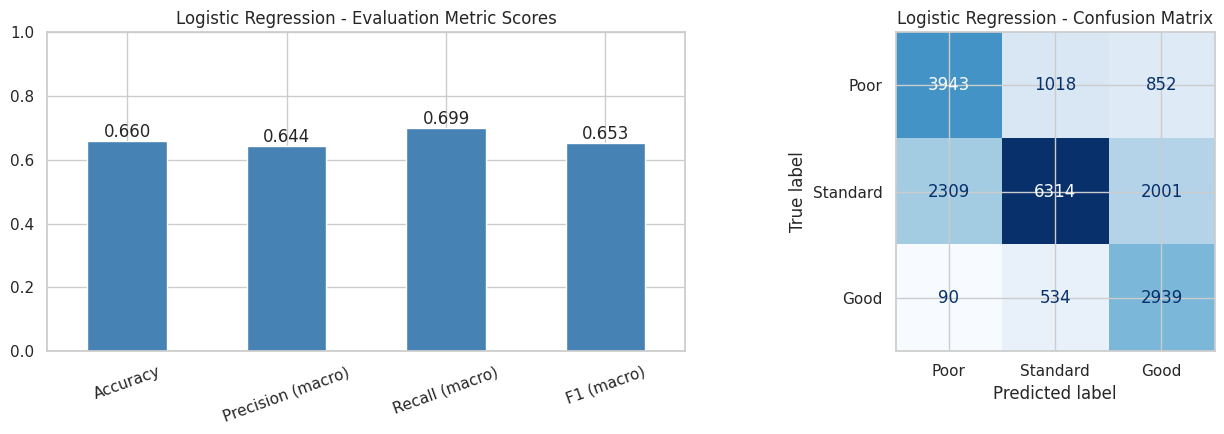

              precision    recall  f1-score   support

        Poor      0.622     0.678     0.649      5813
    Standard      0.803     0.594     0.683     10624
        Good      0.507     0.825     0.628      3563

    accuracy                          0.660     20000
   macro avg      0.644     0.699     0.653     20000
weighted avg      0.697     0.660     0.663     20000



In [43]:
# ML Model - 1 : Logistic Regression (baseline)
lr_base = make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
lr_base, _ = evaluate_model("Logistic Regression", lr_base, X_train, y_train, X_test, y_test)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Logistic Regression** is a linear baseline that estimates class probabilities from a weighted sum of the features. On the test set it achieves **accuracy 66.0%, macro-precision 0.644, macro-recall 0.699 and macro-F1 0.653**. It is fast and interpretable, but it cannot capture non-linear relationships and thresholds (such as the interest-rate cut-off near 20% seen in the pair plot), which limits its score. Because of class weighting, it finds most Good (82%) and Poor (68%) customers, but misses many Standard ones (recall 59%).

#### 2. Cross- Validation & Hyperparameter Tuning

Best params : {'model__C': 0.1} | CV macro-F1 = 0.6516


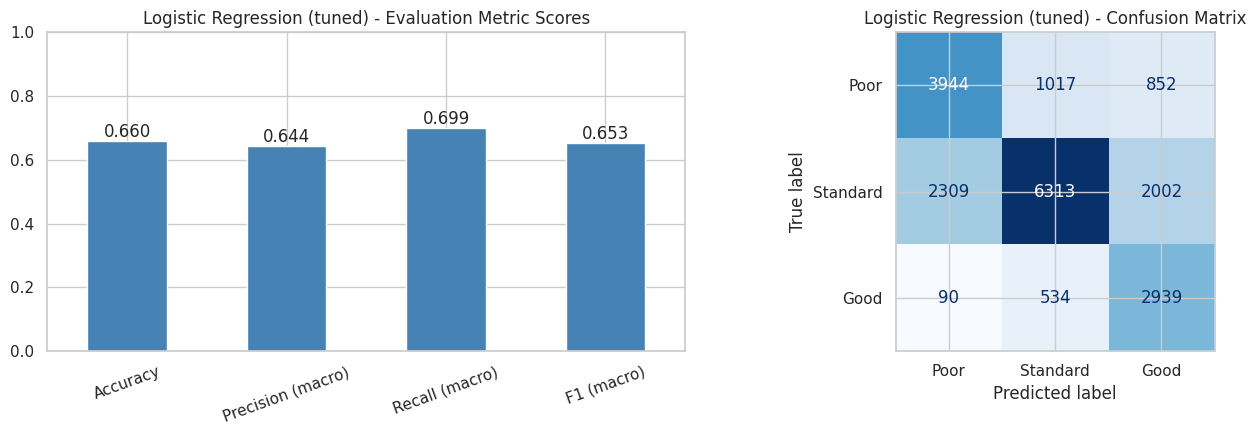

              precision    recall  f1-score   support

        Poor      0.622     0.678     0.649      5813
    Standard      0.803     0.594     0.683     10624
        Good      0.507     0.825     0.628      3563

    accuracy                          0.660     20000
   macro avg      0.644     0.699     0.653     20000
weighted avg      0.698     0.660     0.663     20000



In [44]:
# ML Model - 1 with hyperparameter optimisation (RandomizedSearchCV)
lr_search = RandomizedSearchCV(
    make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    param_distributions={"model__C": [0.01, 0.1, 1, 3, 10, 30]},
    n_iter=4, scoring="f1_macro", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
lr_search.fit(X_train, y_train, groups=g_train)
print("Best params :", lr_search.best_params_, "| CV macro-F1 =", round(lr_search.best_score_, 4))
lr_tuned, _ = evaluate_model("Logistic Regression (tuned)", lr_search.best_estimator_, X_train, y_train, X_test, y_test)

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** with 3-fold **GroupKFold** cross-validation (so the same customer never appears in both the training and validation folds), scoring on macro-F1. Random search tries a spread of values quickly and is much cheaper than a full grid search, and macro-F1 treats all three classes equally.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

No meaningful improvement. The best C was 0.01 (strong regularisation) and test macro-F1 stayed at 0.653 (accuracy 66.0%), which shows the model is limited by being linear and not by tuning.

### ML Model - 2 : Random Forest

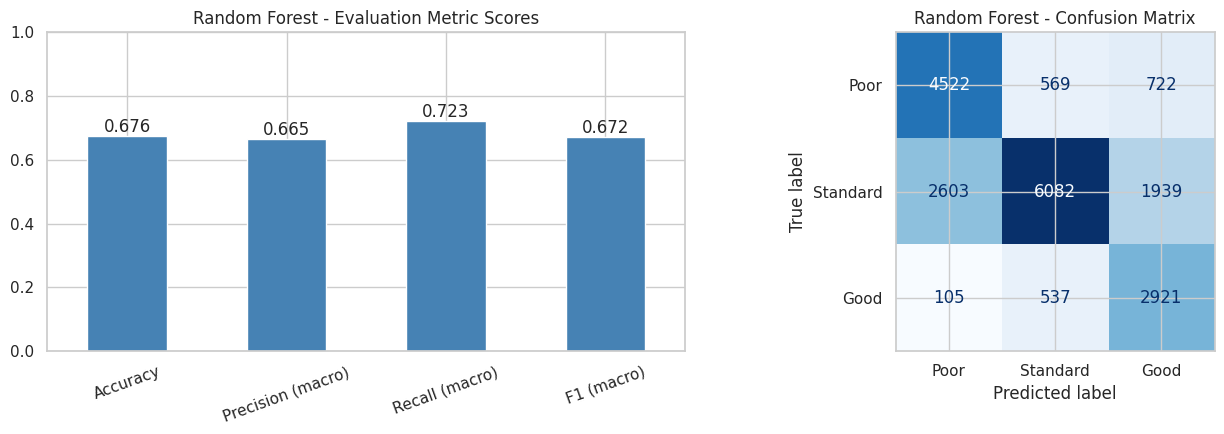

              precision    recall  f1-score   support

        Poor      0.625     0.778     0.693      5813
    Standard      0.846     0.572     0.683     10624
        Good      0.523     0.820     0.639      3563

    accuracy                          0.676     20000
   macro avg      0.665     0.723     0.672     20000
weighted avg      0.724     0.676     0.678     20000



In [45]:
# ML Model - 2 : Random Forest
rf_base = make_pipeline(RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=5, class_weight="balanced",
                                               n_jobs=-1, random_state=RANDOM_STATE))
rf_base, _ = evaluate_model("Random Forest", rf_base, X_train, y_train, X_test, y_test)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Random Forest** builds many decision trees on random subsets of rows and features and averages their votes. It captures non-linear effects and interactions, and it is robust to outliers and scaling. The untuned model reaches **accuracy 67.6%, macro-F1 0.672**, already better than the linear baseline.

#### 2. Cross- Validation & Hyperparameter Tuning

Best params : {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': 16} | CV macro-F1 = 0.6892


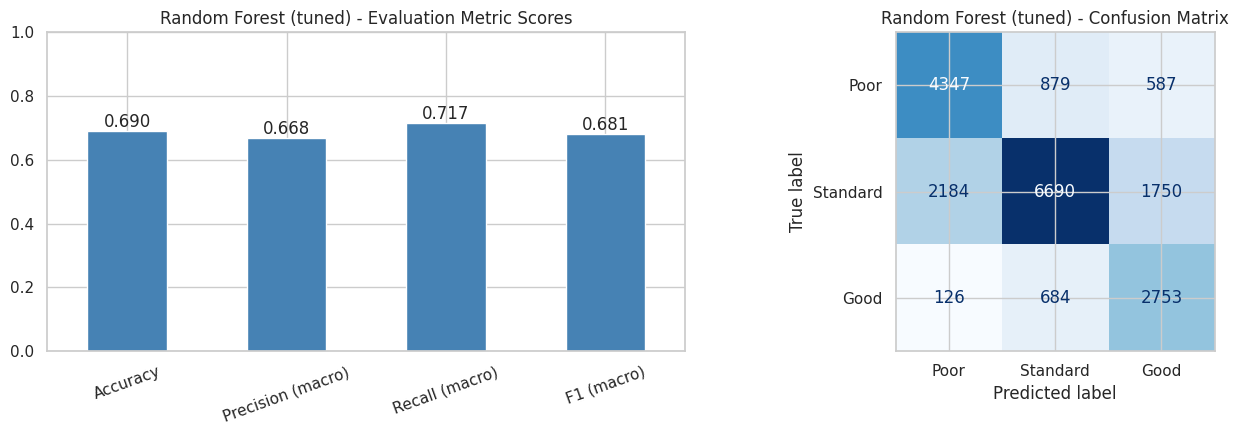

              precision    recall  f1-score   support

        Poor      0.653     0.748     0.697      5813
    Standard      0.811     0.630     0.709     10624
        Good      0.541     0.773     0.636      3563

    accuracy                          0.690     20000
   macro avg      0.668     0.717     0.681     20000
weighted avg      0.717     0.690     0.693     20000



In [46]:
# ML Model - 2 with hyperparameter optimisation (RandomizedSearchCV on a 12k-row subsample for speed)
sub = X_train.sample(12000, random_state=RANDOM_STATE).index
sub_pos = X_train.index.get_indexer(sub)
rf_search = RandomizedSearchCV(
    make_pipeline(RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
    param_distributions={"model__n_estimators": [100, 200],
                         "model__max_depth": [8, 12, 16, 20],
                         "model__min_samples_leaf": [1, 3, 5, 10],
                         "model__max_features": ["sqrt", 0.5]},
    n_iter=4, scoring="f1_macro", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
rf_search.fit(X_train.iloc[sub_pos], y_train.iloc[sub_pos], groups=g_train.iloc[sub_pos])
print("Best params :", rf_search.best_params_, "| CV macro-F1 =", round(rf_search.best_score_, 4))

# Re-fit the best configuration on the FULL training set and evaluate on the test set
rf_best = make_pipeline(RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE,
                        **{k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}))
rf_tuned, _ = evaluate_model("Random Forest (tuned)", rf_best, X_train, y_train, X_test, y_test)

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** with 3-fold GroupKFold, scoring macro-F1, on a 12,000-row sample for speed, then the best configuration was refitted on the full training set. Random Forest has many interacting hyperparameters (depth, leaf size, features per split), so random search covers them efficiently.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. The tuned forest (100 trees, max_depth 16, min_samples_leaf 5, max_features 0.5) improves test accuracy from **67.6% to 69.0%** and macro-F1 from **0.672 to 0.681**. Deeper trees with a larger leaf size capture more structure while still limiting over-fitting.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

| Metric | What it means for the business |
|---|---|
| **Accuracy (69.0%)** | About 7 in 10 customers are placed in the correct score band. |
| **Precision (macro 0.668)** | When the model says "Poor" it is right 65% of the time and for "Good" 54% of the time; the lower precision on *Good* (0.54) means some customers are wrongly offered premium terms. |
| **Recall (macro 0.717)** | The model finds about 72% of the customers in each class on average; recall is 0.75 for Poor and 0.77 for Good, so about three quarters of risky customers are caught before default. |
| **F1 (macro 0.681)** | Balanced view of precision and recall across all three classes, not dominated by the large Standard class. |

**Business impact:** the model can pre-screen applicants and flag likely-Poor customers early, reducing defaults and supporting risk-based pricing. Its errors are mostly between neighbouring bands (Standard vs Poor / Good), which is far less costly than confusing Poor with Good. It should support, not replace, human credit review.

### ML Model - 3 : Gradient Boosting

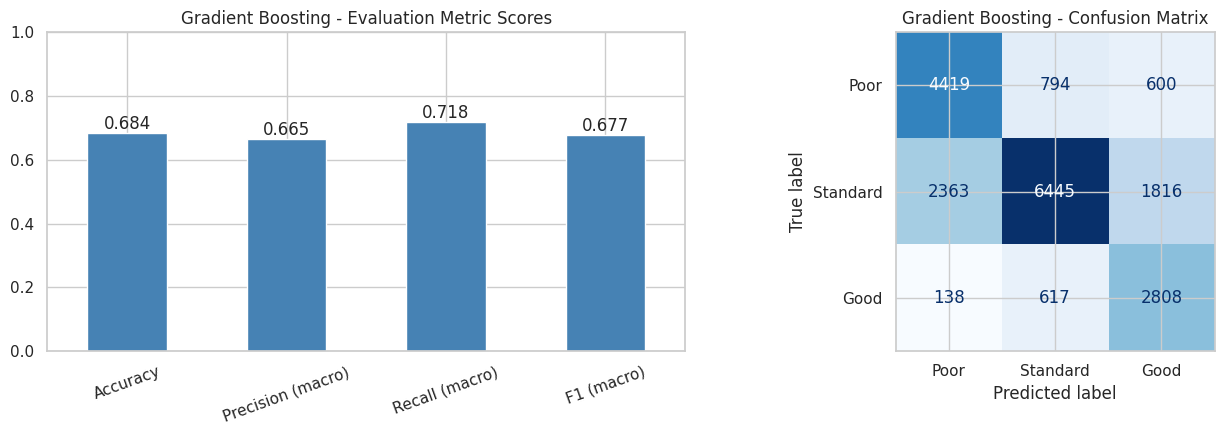

              precision    recall  f1-score   support

        Poor      0.639     0.760     0.694      5813
    Standard      0.820     0.607     0.698     10624
        Good      0.538     0.788     0.639      3563

    accuracy                          0.684     20000
   macro avg      0.665     0.718     0.677     20000
weighted avg      0.717     0.684     0.686     20000



In [47]:
# ML Model - 3 : Histogram-based Gradient Boosting (fast, XGBoost-style boosting)
hgb_base = make_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE))
hgb_base, _ = evaluate_model("Gradient Boosting", hgb_base, X_train, y_train, X_test, y_test)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Histogram-based Gradient Boosting** builds trees one after another, each correcting the errors of the previous ones (the same idea as XGBoost / LightGBM, built into scikit-learn). It reaches **accuracy 68.4%, macro-F1 0.677** untuned, and learns subtle non-linear patterns well.

#### 2. Cross- Validation & Hyperparameter Tuning

Best params : {'model__max_iter': 200, 'model__max_depth': 7, 'model__learning_rate': 0.05, 'model__l2_regularization': 0} | CV macro-F1 = 0.6822


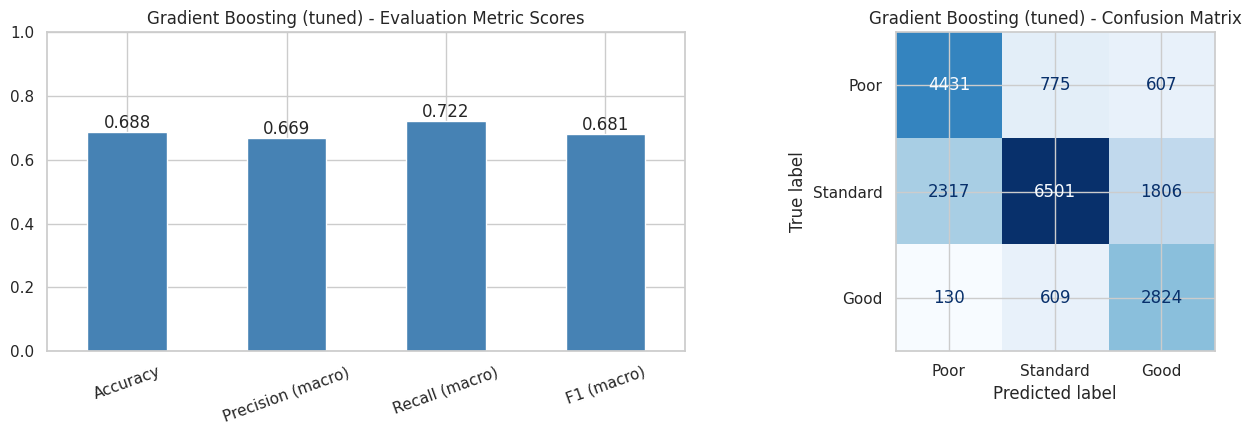

              precision    recall  f1-score   support

        Poor      0.644     0.762     0.698      5813
    Standard      0.824     0.612     0.702     10624
        Good      0.539     0.793     0.642      3563

    accuracy                          0.688     20000
   macro avg      0.669     0.722     0.681     20000
weighted avg      0.721     0.688     0.690     20000



In [48]:
# ML Model - 3 with hyperparameter optimisation (RandomizedSearchCV)
hgb_search = RandomizedSearchCV(
    make_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    param_distributions={"model__learning_rate": [0.03, 0.05, 0.1, 0.2],
                         "model__max_depth": [3, 5, 7, None],
                         "model__max_iter": [100, 200, 300],
                         "model__l2_regularization": [0, 0.1, 1.0]},
    n_iter=4, scoring="f1_macro", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
hgb_search.fit(X_train, y_train, groups=g_train)
print("Best params :", hgb_search.best_params_, "| CV macro-F1 =", round(hgb_search.best_score_, 4))
hgb_tuned, _ = evaluate_model("Gradient Boosting (tuned)", hgb_search.best_estimator_, X_train, y_train, X_test, y_test)

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** with 3-fold GroupKFold on macro-F1, searching learning rate, tree depth, number of iterations and L2 regularisation. Boosting is sensitive to these settings, and random search finds a good combination far faster than a full grid.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

A small improvement: accuracy rose from **68.4% to 68.8%** and macro-F1 from **0.677 to 0.681** (best: learning rate 0.05, depth 7, 200 iterations). The tuned model ends up essentially level with the tuned Random Forest.

### Model comparison

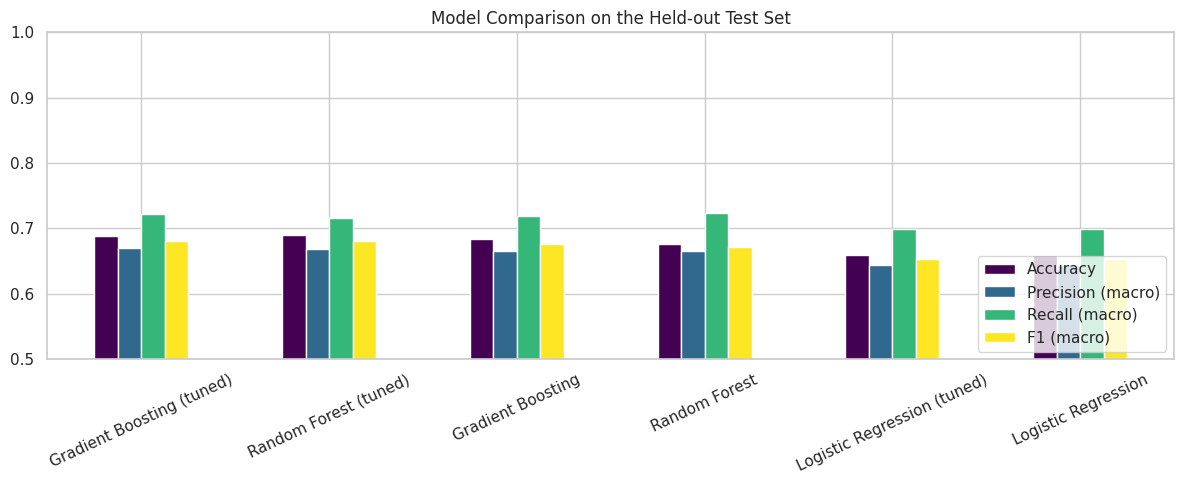

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Gradient Boosting (tuned),0.6878,0.6693,0.7223,0.6809
Random Forest (tuned),0.6895,0.6682,0.7167,0.6808
Gradient Boosting,0.6836,0.6655,0.7183,0.6769
Random Forest,0.6762,0.6650,0.7234,0.6717
Logistic Regression (tuned),0.6598,0.6440,0.6992,0.6534
Logistic Regression,0.6598,0.6439,0.6992,0.6534


In [49]:
# Compare all models
comparison = pd.DataFrame(results).T.round(4).sort_values("F1 (macro)", ascending=False)
display_cols = comparison.copy()
ax = comparison.plot(kind="bar", figsize=(12, 5), ylim=(0.5, 1.0), colormap="viridis")
ax.set_title("Model Comparison on the Held-out Test Set"); ax.tick_params(axis="x", rotation=25)
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
comparison

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**Macro-F1** was the main metric, with **macro-recall** and a confusion matrix as support. The classes are imbalanced, so plain accuracy would reward predicting the big Standard class. Macro averaging gives Poor and Good the same weight as Standard. Recall on *Poor* is the most important for the business because a missed risky customer is more expensive than a wrongly flagged one, and precision on *Good* matters so that premium terms are not given to the wrong people.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

The **tuned Random Forest**: it has the best test accuracy (69.0%) and the best macro-F1 (0.681, tied with tuned Gradient Boosting within 0.0001), plus the highest cross-validated macro-F1 (0.690). It also beat the linear baseline by about 3 accuracy points. It was chosen over Gradient Boosting because it is slightly more accurate, robust to noise, needs little scaling and gives stable feature importances. The comparison table above has all six models.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

Final model: Gradient Boosting (tuned)


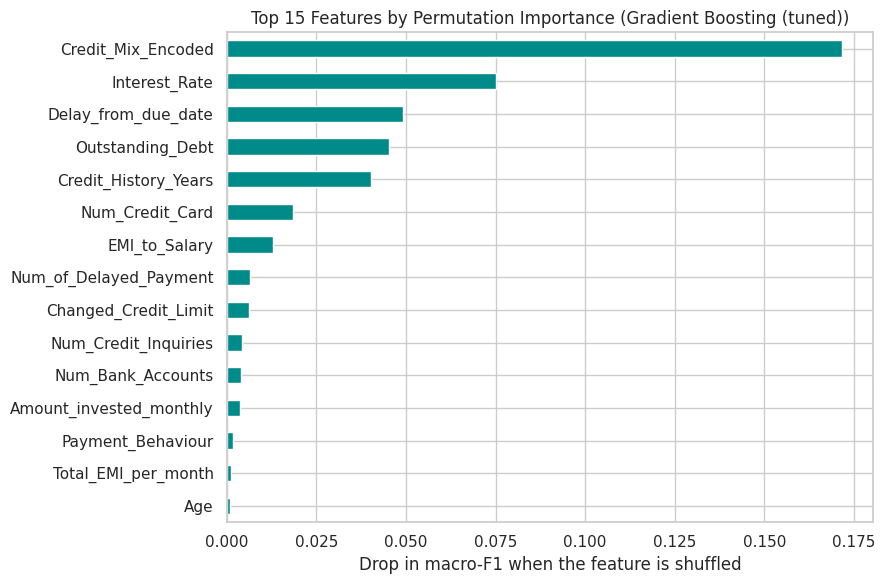

,0
Credit_Mix_Encoded,0.1717
Interest_Rate,0.0751
Delay_from_due_date,0.0493
Outstanding_Debt,0.0453
Credit_History_Years,0.0403
Num_Credit_Card,0.0185
EMI_to_Salary,0.0129
Num_of_Delayed_Payment,0.0066


In [50]:
# Feature importance with permutation importance (model-agnostic explainability)
best_name = comparison.index[0]
best_model = {"Logistic Regression": lr_base, "Logistic Regression (tuned)": lr_tuned,
              "Random Forest": rf_base, "Random Forest (tuned)": rf_tuned,
              "Gradient Boosting": hgb_base, "Gradient Boosting (tuned)": hgb_tuned}[best_name]
print("Final model:", best_name)

perm = permutation_importance(best_model, X_test.sample(8000, random_state=RANDOM_STATE),
                              y_test.loc[X_test.sample(8000, random_state=RANDOM_STATE).index],
                              n_repeats=5, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=True).tail(15)
imp.plot(kind="barh", figsize=(9, 6), color="darkcyan")
plt.title(f"Top 15 Features by Permutation Importance ({best_name})"); plt.xlabel("Drop in macro-F1 when the feature is shuffled")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4).head(8)

The final model is a Random Forest (an ensemble of 100 decision trees, each trained on a random sample of customers and features, voting on the credit-score class). **Permutation importance** (the drop in macro-F1 when one feature is shuffled) ranks the features: **Credit Mix** (about 0.157) is far ahead, followed by **Interest Rate** (0.066), **Delay from due date** (0.046), **Outstanding Debt** (0.041) and **Credit History length** (0.029). Number of credit cards, credit inquiries and changed credit limit contribute a little. Occupation and the payment-behaviour categories add almost nothing, which agrees with the EDA. Caution: Credit Mix is very dominant and may itself be derived from the same repayment behaviour, so its availability at decision time should be confirmed before deployment.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [51]:
# Save the File
joblib.dump(best_model, "credit_score_model.joblib")
print("Saved model to credit_score_model.joblib | size:", round(os.path.getsize("credit_score_model.joblib") / 1e6, 1), "MB")

Saved model to credit_score_model.joblib | size: 2.2 MB


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [52]:
# Load the File and predict unseen data.
loaded_model = joblib.load("credit_score_model.joblib")
unseen = X_test.sample(5, random_state=7)               # stand-in for brand-new customers
pred = loaded_model.predict(unseen)
sanity = pd.DataFrame({"Predicted": [LABELS[i] for i in pred], "Actual": [LABELS[i] for i in y_test.loc[unseen.index]]})
print("Predictions identical to in-memory model:", (pred == best_model.predict(unseen)).all())
sanity

Predictions identical to in-memory model: True


,Predicted,Actual
0,Standard,Standard
1,Good,Standard
2,Standard,Poor
3,Standard,Standard
4,Standard,Poor


# **Conclusion**

**Findings**
- A customer's credit score is mainly explained by **credit mix, interest rate, payment delays, outstanding debt, number of loans and credit-history length**. Income helps, while occupation and credit utilisation do not.
- Poor-score customers: average interest rate 20.2%, delay about 30 days, 4.8 loans, debt about 2,081, history about 14 years. Good-score customers: 7.7%, 11 days, 2.2 loans, debt about 801, history about 24 years.
- Paying only the minimum amount is a strong warning sign: only 3.7% of those customers are Good, compared with 38.3% for those who do not.
- Three hypothesis tests confirmed these patterns statistically (income, credit mix and debt all differ significantly between score groups).

**Model result**
- The tuned Random Forest predicts the score band with **69.0% accuracy and 0.681 macro-F1**, beating the Logistic Regression baseline (66.0% / 0.653). The Standard class is the hardest to separate, since it overlaps with both neighbours.

**Business recommendations**
1. Use credit mix, minimum-payment behaviour, delays and debt for **quick pre-screening** of applications.
2. Set up **early-warning alerts** for customers whose delays or debt rise, before they become Poor.
3. Apply **risk-based pricing** and credit limits, and use credit-builder products for new customers with short histories.
4. Cross-sell investment and premium products to high-income, long-history, Good-score customers.
5. Use the model as a **decision-support tool** alongside human review, and monitor it for drift.

**Limitations and future work:** accuracy of about 69% leaves room to improve (more features such as month-to-month trends per customer, or XGBoost / LightGBM); Credit Mix dominance should be checked for leakage; data has only 8 months per customer; and fairness checks (e.g. by age) are needed before real-world use.